# Fixing errors in the iteration-7 research record — `eval.py` stage A and items 0a/0b

**Artifact `art_vjtPMtWGMjsB` (evaluation, iteration 8, Step 0).** This evaluation repairs the written record of a
research project on *how "creativity" in an LLM's choice of algorithm can be steered*: does Qwen3-8B always write the
"average" algorithm (Dijkstra for shortest path, union-find for connected components, a full sort for the kth
smallest), and do prompt bans, forced prompts or activation-space interventions move it to other algorithms? The
iteration-7 report received a blocking review with 11 items (0a–0k). `eval.py` answers all of them: it re-derives
every disputed number from the raw files, writes **84 machine-checkable report edits** (each `old_text` occurs once in
the report) and a **141-value ledger** (value as recorded in the report, recomputed value, status MATCH / CORRECTED /
NEW / CARRIED, source `artifact:file#key`), and runs two independent stdlib audits with placebos.

`eval.py` itself is an orchestrator: `uv run eval.py --stages all` runs `s0, a, b, …, k, apply, audit, out`, and the
logic lives in `sections/*.py` and `labeller_v2/*.py`, which the cells below reproduce.

**The headline correction (item 0a).** Every program generated in the DAS experiment (exp33, Qwen3-8B) is labelled with
the algorithm it implements by a runtime rule (a sandboxed trace with probes) and an AST rule. On *kth smallest* both
rules missed **counting sort in dictionary form** — `Counter(nums)` (or a dict of counts) walked in sorted key order.
So the full-state exchange of the forced counting-sort source looked like 0/30 counting sort (29 "other"), the
denominator of the pooled DAS recovery shrank, and the recovery read **1.59** instead of **≈1.0**.

**What this notebook runs, with minimal changes to the original code**

| Step | Original module | In the demo |
|-|-|-|
| A2 labeller validation (references, gold set, 5 constructed controls) | `sections/a_labeller.py` | stored result (needs the sandboxed tracer and the bench's hidden tests) |
| A3 relabel of the kth-smallest programs with the extended labeller | `sections/a_labeller.py`, `labeller_v2/` | **runs**; the new AST rule runs live, the runtime labels come from the tracer's cached output |
| A4 adjudication: rule vs two gated LLM judges vs manual reads | `sections/a_adjudicate.py`, `sections/manual_reads.py` | **runs** on the cached judge answers (as `eval.py` does on any rerun) |
| A5 recompute of exp33's pooled recovery with its own slot bootstrap, placebo first | `sections/a_recompute.py` | **runs** |
| Items 0a and 0b: ledger values and report edits, new Table 297b | `sections/item_a.py`, `sections/item_b.py` | **run** |
| `write_corrections()` | `eval.py` | **runs** on items 0a and 0b |
| s0, items 0c–0k, apply, audit, out | `sections/s0_apply.py`, `item_cde/f/ghijk.py`, `audit/`, `outputs.py` | not run: they need the 1.3 MB report and other experiments' files |

**Data.** `mini_demo_data.json` holds one example per exp33 cell (task × arm) that these stages read — 86 cells, 2,172
generated programs — plus the small exp33 result files they read and the cached tracer and judge outputs. It is loaded
from GitHub, with a local fallback. Runtime: well under a minute after the install cell.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- eval.py
import argparse
import json
import resource
import subprocess
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger

# --- sections/*.py and labeller_v2/*.py
import ast
import hashlib
import math
import random
import re
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np

# --- notebook additions
from types import SimpleNamespace  # stands in for `from sections import <module> as X`
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-8/evaluation-7/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# Until this demo is pushed, the URL may still serve an older demo's file with another layout: use the local copy then.
if "metadata" not in data or "datasets" not in data:
    print("GitHub file has an older layout, using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
_m = data["metadata"]
print(_m["description"])
print(f"\n{_m['n_cells']} cells, {_m['n_rows']} generated programs; read {_m['read_date']}")
print(pd.DataFrame([{"task": e["task"], "arm": e["arm"], "n": e["n_rows"], "role": "; ".join(e["role"]),
                     "old labels": e["old_label_counts"]} for e in data["datasets"][0]["examples"]]).head(12).to_string())

GitHub file has an older layout, using local mini_demo_data.json
Curated input of code_demo.ipynb: the exp33 label rows (one example per task x arm cell) and the small exp33 result files read by STAGE a and items 0a/0b of eval.py (iteration-8 Step 0 record repair, artifact art_vjtPMtWGMjsB), plus the cached tracer and judge outputs that the notebook cannot rerun.

86 cells, 2172 generated programs; read 2026-10-23
   task               arm   n                                                                 role                              old labels
0    T2           F3_dial   4                              A4 adjudication (old other share > 20%)             {'other': 3, 'dijkstra': 1}
1    T2      PAD0_bf_spfa   4                              A4 adjudication (old other share > 20%)             {'dijkstra': 3, 'other': 1}
2    T2           F1_dial   4                              A4 adjudication (old other share > 20%)             {'dijkstra': 3, 'other': 1}
3    T2           F2_dial 

## Config

Every tunable parameter of the demo. The defaults are the original values: the whole computation takes seconds, so
nothing needs scaling down. `BOOT` is special: the A5 placebo checks that the port reproduces exp33's published
bootstrap intervals to 1e-9, which only holds with exp33's own 2,000 resamples, so any other value makes stage a stop
on purpose (`RuntimeError: A5 placebo failed`).

In [5]:
# ---- Config -------------------------------------------------------------------------------------------------------
STAGES = ["a", "b"]          # "a" = stage A (labeller, adjudication, recompute) + item 0a; "b" = item 0b (needs "a").
                              # Original: `uv run eval.py --stages all` = s0,a,b,c,d,e,f,g,h,i,j,k,apply,audit,out
BOOT = 2000                   # slot-bootstrap resamples of the pooled-recovery CI (original and exp33: 2000)
SEED = 20261022               # exp33's bootstrap seed (original)
N_WORKERS = 12   # threads that label the kth-smallest programs (original: 12)
DEMO_ROOT = Path("demo_out")  # stage outputs: results/, tables/, audit/, logs/, corrections.json (original: next to eval.py)

## `eval.py`: setup, stage list, memory cap

The top of `eval.py`: logging to stdout and `logs/run.log`, the stage list (`ALL`), the map from stage letters to
review items, and the address-space cap. The only change: `ROOT` is the demo output folder instead of the folder that
holds `eval.py`.

In [6]:
ROOT = DEMO_ROOT  # original: Path(__file__).resolve().parent; sys.path.insert(0, str(ROOT)) is not needed here
(ROOT / "logs").mkdir(parents=True, exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(ROOT / "logs" / "run.log", rotation="30 MB", level="DEBUG")

ALL = ["s0", "a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "apply", "audit", "out"]
ITEM_STAGES = {"a": "0a", "b": "0b", "c": "0c", "d": "0d", "e": "0e", "f": "0f", "g": "0g", "h": "0h", "i": "0i",
               "j": "0j", "k": "0k"}


def _limit_memory(gb: float = 16.0) -> None:
    b = int(gb * 1024 ** 3)
    resource.setrlimit(resource.RLIMIT_AS, (b * 3, b * 3))

## `sections/common.py`: paths, exact statistics, correction records

The shared helpers used by stages a and b: the source-reference format, JSON/CSV writers, the exact Clopper-Pearson
interval (regularised incomplete beta by bisection), Cohen's kappa, and the two record builders — `value()` (one ledger
entry: recorded, recomputed, status; MATCH is *asserted* to be within tolerance) and `edit()` (one report edit).
The rest of `common.py` (Wilson, McNemar, Newcombe, Fisher, Spearman, the residual-claim lint) serves items 0c–0k.

**The one change:** `dep()` returns a key instead of a path inside a dependency workspace, and `read_json` /
`read_jsonl` serve those keys from `DEMO_FILES`, built from `mini_demo_data.json` in the next cell. Every call site in
the stage code below stays exactly as written, e.g. `read_jsonl(dep("exp33", "data/labels.jsonl"))`.

In [7]:
RESULTS = ROOT / "results"
TABLES = ROOT / "tables"
AUDIT = ROOT / "audit"
READ_DATE = "2026-10-23"
# artifact id -> folder name under ITER7 (declared dependencies plus the evaluation read by absolute path)
ARTIFACTS = {
    "art_veI9l_Rb9wDY": "gen_art_experiment_33",
    "art_pHL7LWNhpcCS": "gen_art_experiment_34",
    "art_MZAfDPVhM6Ui": "gen_art_experiment_35",
    "art_8O5eaNc5gxJs": "gen_art_experiment_36",
    "art_VhaHGe7SxV95": "gen_art_experiment_37",
    "art_HY7uYZz-OjRW": "gen_art_experiment_38",
    "art_LzP2qPwUrANz": "gen_art_evaluation_6",
}
SHORT = {"art_veI9l_Rb9wDY": "exp33", "art_pHL7LWNhpcCS": "exp34", "art_MZAfDPVhM6Ui": "exp35",
         "art_8O5eaNc5gxJs": "exp36", "art_VhaHGe7SxV95": "exp37", "art_HY7uYZz-OjRW": "exp38",
         "art_LzP2qPwUrANz": "eval6"}
BY_SHORT = {v: k for k, v in SHORT.items()}


def dep(short: str, rel: str = "") -> tuple[str, str]:
    """Demo: the key of a dependency file in DEMO_FILES (original: its Path inside the dependency workspace, found
    under DEP_ROOT by folder name or by artifact id)."""
    return (short, rel)


def src_ref(short: str, rel: str, key: str = "") -> str:
    """Source string '<artifact_id>:<relative path>#<key>' used in every correction record."""
    return f"{BY_SHORT[short]}:{rel}" + (f"#{key}" if key else "")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def _read_text(p: Path | tuple[str, str]) -> str:
    """Demo: a dep() key is served from DEMO_FILES; every other path is a real file (the stage outputs)."""
    return DEMO_FILES[p] if isinstance(p, tuple) else Path(p).read_text()


def read_json(p: Path) -> Any:
    return json.loads(_read_text(p))  # original: json.loads(Path(p).read_text())


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    return [json.loads(l) for l in _read_text(p).splitlines() if l.strip()]  # original: Path(p).read_text()


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=1, ensure_ascii=False, default=_default))


def _default(o: Any) -> Any:
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, "item"):
        return o.item()
    raise TypeError(f"not serialisable: {type(o)}")


def write_csv(p: Path, rows: list[dict[str, Any]], cols: list[str] | None = None) -> None:
    import csv
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    cols = cols or (list(rows[0].keys()) if rows else [])
    with p.open("w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if r.get(k) is None else r.get(k)) for k in cols})


# ------------------------------------------------------------------------------------------------ exact statistics
def _betacf(a: float, b: float, x: float) -> float:
    MAXIT, EPS, FPMIN = 300, 3e-16, 1e-300
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c, d = 1.0, 1.0 - qab * x / qap
    d = 1.0 / (d if abs(d) > FPMIN else FPMIN)
    h = d
    for m in range(1, MAXIT + 1):
        m2 = 2 * m
        aa = m * (b - m) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d
        d = 1.0 / (d if abs(d) > FPMIN else FPMIN)
        c = 1.0 + aa / c
        c = c if abs(c) > FPMIN else FPMIN
        h *= d * c
        aa = -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d
        d = 1.0 / (d if abs(d) > FPMIN else FPMIN)
        c = 1.0 + aa / c
        c = c if abs(c) > FPMIN else FPMIN
        de = d * c
        h *= de
        if abs(de - 1.0) < EPS:
            break
    return h


def betainc(a: float, b: float, x: float) -> float:
    """Regularised incomplete beta I_x(a, b)."""
    if x <= 0.0:
        return 0.0
    if x >= 1.0:
        return 1.0
    lbt = math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + a * math.log(x) + b * math.log(1.0 - x)
    bt = math.exp(lbt)
    if x < (a + 1.0) / (a + b + 2.0):
        return bt * _betacf(a, b, x) / a
    return 1.0 - bt * _betacf(b, a, 1.0 - x) / b


def beta_ppf(q: float, a: float, b: float) -> float:
    lo, hi = 0.0, 1.0
    for _ in range(200):
        mid = (lo + hi) / 2
        if betainc(a, b, mid) < q:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def clopper_pearson(k: int, n: int, alpha: float = 0.05) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    lo = 0.0 if k == 0 else beta_ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta_ppf(1 - alpha / 2, k + 1, n - k)
    return [lo, hi]


def cohen_kappa(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    if pe >= 1.0:
        return 1.0 if po == 1.0 else 0.0
    return (po - pe) / (1 - pe)


def fmt(x: float | None, nd: int = 2) -> str:
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "-"
    return f"{x:.{nd}f}"


# ------------------------------------------------------------------------------------------------ correction records
VALUES: list[dict[str, Any]] = []


def value(name: str, recorded: Any, recomputed: Any, status: str, source: str, tolerance: float | str = 0.005,
          item: str = "", note: str = "") -> dict[str, Any]:
    """One traced value: recorded (as printed in current_report.md), recomputed (from the raw file), status in
    MATCH | CORRECTED | NEW | CARRIED. MATCH requires |recorded - recomputed| <= tolerance for numbers."""
    assert status in ("MATCH", "CORRECTED", "NEW", "CARRIED"), status
    rec = {"name": name, "item": item, "recorded": recorded, "recomputed": recomputed, "status": status,
           "tolerance": tolerance, "source": source}
    if note:
        rec["note"] = note
    if status == "MATCH" and isinstance(recorded, (int, float)) and isinstance(recomputed, (int, float)):
        assert abs(float(recorded) - float(recomputed)) <= float(tolerance) + 1e-12, (name, recorded, recomputed)
    VALUES.append(rec)
    return rec


def auto_status(recorded: float | None, recomputed: float, tol: float = 0.005) -> str:
    if recorded is None:
        return "NEW"
    return "MATCH" if abs(recorded - recomputed) <= tol + 1e-12 else "CORRECTED"


SUFFIX = " (iteration-8 correction)"


def edit(cid: str, item: str, section: str, old: str, new: str, kind: str = "prose", why: str = "",
         values: list[str] | None = None) -> dict[str, Any]:
    """One machine-checkable edit of the report. Prose edits must end with the iteration-8 suffix."""
    return {"id": cid, "item": item, "section": section, "kind": kind, "old_text": old, "new_text": new, "why": why,
            "value_names": values or []}

### Demo adapter: the exp33 files, served from the loaded data

`DEMO_FILES` maps `(artifact, relative path)` to the text the stages would read from disk:
`data/labels.jsonl` (the generated programs of the 86 cells, in their original file order — A4's fixed-seed agreement
sample depends on it) and the small exp33 result files (`p1.json` with the published recoveries, `targets_*`, `kstar_*`,
`site_*`, `novelty_audit.json`, `randinit_*`). Each label row carries exp33's fields (`arm`, `slot_index`, `passed`,
`label`, `runtime_label`, `ast_label`, `code`, …) plus the cached tracer and judge outputs used further down.

In [8]:
CELLS = data["datasets"][0]["examples"]
LABEL_ROWS = sorted((r for ex in CELLS for r in ex["rows"]), key=lambda r: r["row_index"])  # labels.jsonl order
DEMO_FILES = {("exp33", rel): json.dumps(obj) for rel, obj in data["metadata"]["exp33_files"].items()}
DEMO_FILES[("exp33", "data/labels.jsonl")] = "\n".join(json.dumps(r) for r in LABEL_ROWS)
C = SimpleNamespace(VALUES=VALUES, READ_DATE=READ_DATE)  # stands in for `from sections import common as C`
print(f"{len(LABEL_ROWS)} label rows in {len(CELLS)} cells:", dict(Counter(r["task"] for r in LABEL_ROWS)))
print("served files:", ", ".join(rel for _, rel in DEMO_FILES))

2172 label rows in 86 cells: {'T2': 870, 'T03': 552, 'T10': 750}
served files: results/targets_T2.json, results/kstar_T2.json, results/site_T2.json, results/targets_T10.json, results/kstar_T10.json, results/site_T10.json, results/targets_T03.json, results/kstar_T03.json, results/site_T03.json, results/p1.json, results/novelty_audit.json, results/randinit_T2.json, results/randinit_ly_T2.json, data/labels.jsonl


## A1: the extended kth-smallest AST labeller (`labeller_v2/ast_rules_v2.py`)

`labeller_v2/` is a byte-identical copy of the frozen bench rules plus **one** recogniser. The cell keeps the parts the
kth-smallest task (T03) uses: the AST feature bag `F`, the heap test, the T03 rule, and the dispatcher. The added code is
`_freq_maps` (names bound to a frequency map: `Counter(nums)`, `defaultdict(int)`, or a dict filled with
`m[x] = m.get(x, 0) + 1` / `m[x] += 1`) and `_dict_counting_sort` (that map is walked in sorted key order — or the
sorted distinct values are walked against it — until rank k is covered, with no sort of the whole input and no heap),
called from `t03` right after the existing array-of-counts test. Note the old line that follows it: a `Counter` plus a
`sorted(...keys/items)` returned `"unknown"` — that is where the dictionary form used to fall through.

In [9]:
# labeller_v2/ast_rules_v2.py (the parts used for T03, kth smallest)
class F:
    """AST feature bag of one program."""

    def __init__(self, code: str):
        self.code = code
        self.tree = ast.parse(code)
        self.calls = Counter()
        self.attr_calls = Counter()
        self.imports = set()
        self.names = Counter()
        self.funcs = {}
        self.recursive = set()
        self.max_loop_depth = 0
        self.n_loops = 0
        self.classes = 0
        self.decorators = Counter()
        self.bitand_neg = False
        self.pop0 = 0
        self.pop_noarg = 0
        self.popleft = 0
        self.subscript_nested = 0
        self.consts = Counter()
        for node in ast.walk(self.tree):
            if isinstance(node, ast.Import):
                for a in node.names:
                    self.imports.add(a.name.split(".")[0])
            elif isinstance(node, ast.ImportFrom):
                if node.module:
                    self.imports.add(node.module.split(".")[0])
                for a in node.names:
                    self.imports.add(a.name)
            elif isinstance(node, ast.Call):
                fn = node.func
                if isinstance(fn, ast.Name):
                    self.calls[fn.id] += 1
                elif isinstance(fn, ast.Attribute):
                    self.attr_calls[fn.attr] += 1
                    if isinstance(fn.value, ast.Name):
                        self.calls[f"{fn.value.id}.{fn.attr}"] += 1
                    if fn.attr == "pop":
                        if not node.args:
                            self.pop_noarg += 1
                        elif isinstance(node.args[0], ast.Constant) and node.args[0].value == 0:
                            self.pop0 += 1
                    if fn.attr == "popleft":
                        self.popleft += 1
            elif isinstance(node, ast.Name):
                self.names[node.id] += 1
            elif isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                self.funcs[node.name] = node
                for d in node.decorator_list:
                    dn = d.func if isinstance(d, ast.Call) else d
                    nm = dn.attr if isinstance(dn, ast.Attribute) else (dn.id if isinstance(dn, ast.Name) else "?")
                    self.decorators[nm] += 1
                for sub in ast.walk(node):
                    if isinstance(sub, ast.Call) and isinstance(sub.func, ast.Name) and sub.func.id == node.name:
                        self.recursive.add(node.name)
                    if isinstance(sub, ast.Call) and isinstance(sub.func, ast.Attribute) and sub.func.attr == node.name:
                        self.recursive.add(node.name)
            elif isinstance(node, ast.ClassDef):
                self.classes += 1
            elif isinstance(node, ast.BinOp) and isinstance(node.op, ast.BitAnd):
                for side in (node.left, node.right):
                    if isinstance(side, ast.UnaryOp) and isinstance(side.op, ast.USub):
                        self.bitand_neg = True
            elif isinstance(node, ast.Subscript) and isinstance(node.slice, ast.Subscript):
                self.subscript_nested += 1
            elif isinstance(node, ast.Constant) and isinstance(node.value, (int, str)):
                self.consts[node.value] += 1
        self._loop_depth(self.tree, 0)
        self.low = code.lower()
        self.idents = {n.lower() for n in self.names} | {f.lower() for f in self.funcs}

    def _loop_depth(self, node, d):
        for ch in ast.iter_child_nodes(node):
            if isinstance(ch, (ast.For, ast.While)):
                self.n_loops += 1
                self.max_loop_depth = max(self.max_loop_depth, d + 1)
                self._loop_depth(ch, d + 1)
            elif isinstance(ch, (ast.FunctionDef, ast.Lambda, ast.AsyncFunctionDef, ast.ClassDef)):
                self._loop_depth(ch, 0)
            else:
                self._loop_depth(ch, d)

    def has(self, *names):
        return any(self.calls.get(n) or self.attr_calls.get(n) for n in names)

    def ident(self, *subs):
        return any(any(s in i for s in subs) for i in self.idents)

    def rx(self, pattern):
        return re.search(pattern, self.code) is not None

    @property
    def memo(self):
        return bool(self.decorators.get("lru_cache") or self.decorators.get("cache") or self.ident("memo", "cache"))


def _heapish(f):
    return f.has("heappush", "heappop", "heapify", "heappushpop", "heapreplace", "nlargest", "nsmallest") or \
        f.has("PriorityQueue")


# ------------------------------------------------------------------------------------------------ iteration-8 extension
def _freq_maps(f):
    """Names bound to a frequency map over the input values: Counter(<input>), defaultdict(int) or a dict literal /
    dict() that the program fills with m[x] = m.get(x, 0) + 1 or m[x] += 1 (iteration-8 extension)."""
    direct, cand, counted = set(), set(), set()
    for node in ast.walk(f.tree):
        if isinstance(node, ast.Assign) and len(node.targets) == 1 and isinstance(node.targets[0], ast.Name):
            nm, v = node.targets[0].id, node.value
            if isinstance(v, ast.Call):
                fn = v.func
                fname = fn.id if isinstance(fn, ast.Name) else (fn.attr if isinstance(fn, ast.Attribute) else "")
                if fname == "Counter" and v.args:
                    direct.add(nm)
                elif fname == "defaultdict" and v.args and isinstance(v.args[0], ast.Name) and v.args[0].id == "int":
                    cand.add(nm)
                elif fname == "dict" and not v.args:
                    cand.add(nm)
            elif isinstance(v, ast.Dict) and not v.keys:
                cand.add(nm)
        elif isinstance(node, ast.AugAssign) and isinstance(node.op, ast.Add) and \
                isinstance(node.target, ast.Subscript) and isinstance(node.target.value, ast.Name):
            counted.add(node.target.value.id)
        elif isinstance(node, ast.Assign) and len(node.targets) == 1 and isinstance(node.targets[0], ast.Subscript) \
                and isinstance(node.targets[0].value, ast.Name):
            nm = node.targets[0].value.id
            src = ast.unparse(node.value).replace(" ", "")
            if f"{nm}.get(" in src and src.endswith("+1"):
                counted.add(nm)
    return direct | (cand & counted)


def _dict_counting_sort(f):
    """Counting sort in dictionary form: a frequency map over the input values, iteration over sorted(map),
    sorted(map.keys()) or sorted(map.items()) (or the sorted distinct values) accumulating counts until rank k, or
    expansion of value x count into a list; no sort of the whole input list and no heap."""
    maps = _freq_maps(f)
    if not maps or _heapish(f) or "solve" not in f.funcs:
        return False
    args = f.funcs["solve"].args.args
    inp = args[0].arg if args else "nums"
    sorts_map = False
    for node in ast.walk(f.tree):
        if not isinstance(node, ast.Call):
            continue
        fn = node.func
        if isinstance(fn, ast.Attribute) and fn.attr == "sort" and isinstance(fn.value, ast.Name) and fn.value.id == inp:
            return False  # sorts the whole input list
        if isinstance(fn, ast.Name) and fn.id == "sorted" and node.args:
            a0 = node.args[0]
            if isinstance(a0, ast.Name) and a0.id == inp:
                return False  # sorted(<input>)
            if any(kw.arg == "key" for kw in node.keywords):
                kv = ast.unparse([kw for kw in node.keywords if kw.arg == "key"][0].value)
                if "[1]" in kv or "get" in kv:
                    continue  # sorted by count, not by value
            if isinstance(a0, ast.Name) and a0.id in maps:
                sorts_map = True
            elif isinstance(a0, ast.Call) and isinstance(a0.func, ast.Attribute) and a0.func.attr in ("keys", "items") \
                    and isinstance(a0.func.value, ast.Name) and a0.func.value.id in maps:
                sorts_map = True
            elif isinstance(a0, ast.Call) and isinstance(a0.func, ast.Name) and a0.func.id == "set" and a0.args and \
                    isinstance(a0.args[0], ast.Name) and a0.args[0].id == inp:
                sorts_map = True  # sorted distinct values walked against the frequency map
    if not sorts_map:
        return False
    walks = f.rx(r"\bk\s*-=") or f.rx(r"(>=|<=|<|>)\s*k\b") or f.rx(r"\bk\s*(>=|<=|<|>)") or \
        f.rx(r"\[\s*\w+\s*\]\s*\*\s*\w+") or f.rx(r"\.extend\(") or f.rx(r"\[\s*k\s*-\s*1\s*\]")
    return bool(walks)


def t03(f):
    if f.has("nsmallest", "nlargest"):
        return "size_k_heap"
    if f.has("heapify") and f.has("heappop") and not (f.has("heappush") and f.rx(r"len\(\s*\w+\s*\)\s*>")):
        return "heapify_pop"
    if f.has("heappush", "heappushpop", "heapreplace"):
        if f.rx(r"len\(\s*\w+\s*\)\s*(>|>=|==|<|<=)\s*k") or f.has("heappushpop", "heapreplace"):
            return "size_k_heap"
        if f.has("heappop"):
            return "heapify_pop"
    if f.rx(r"\b5\b") and (f.ident("median", "group", "chunk") or f.rx(r":\s*\w+\s*\+\s*5\]")) and f.recursive | {"x"}:
        if f.ident("median") or f.rx(r"range\([^)]*,\s*5\)"):
            return "median_of_medians"
    if f.rx(r"\[0\]\s*\*\s*\(?\s*(max|hi|high|max_val|maxv|mx|\w+_max|20001|20000|10001)") or \
            (f.ident("count") and f.rx(r"\[0\]\s*\*\s*\(") and f.has("min", "max")) or \
            f.rx(r"for\s+\w+\s+in\s+range\(\s*(min|lo|low|min_val|mn|-\s*10000|offset)\w*") and f.ident("count", "freq"):
        return "counting_sort"
    if _dict_counting_sort(f):  # iteration-8 extension: counting sort, dictionary form (maps to counting_sort)
        return "counting_sort"
    if (f.has("Counter") or f.ident("count", "freq")) and f.rx(r"sorted\(\s*\w+\.?(keys|items)?\(?\)?\s*\)"):
        return "unknown"
    if f.ident("pivot", "partition", "quickselect", "select") and not f.has("sort", "sorted"):
        return "quickselect"
    if f.ident("pivot") and f.recursive:
        return "quickselect"
    if f.has("sorted", "sort") and not f.ident("pivot"):
        return "full_sort"
    if f.ident("pivot"):
        return "quickselect"
    return "unknown"


RULES = {"T03": t03}  # demo: the kth-smallest rule only (original also maps T04 ... T14 and R1 ... R6 to their rules)


def ast_label(task: str, code: str | None) -> str:
    if not code:
        return "invalid"
    try:
        f = F(code)
    except (SyntaxError, ValueError):
        return "invalid"
    if "solve" not in f.funcs:
        return "invalid"
    try:
        return RULES[task](f)
    except (RecursionError, KeyError, TypeError):
        return "unknown"


ast_rules_v2 = SimpleNamespace(ast_label=ast_label)  # stands in for `from labeller_v2 import ast_rules_v2`

### The five constructed controls (`labeller_v2/controls.py`) and one real program

Two positives must become counting sort; three negatives (a dict used as a memo then a full sort, value buckets, a heap
over `Counter` items) must keep their class. A2 checks the *combined* runtime + AST label and the bench's hidden tests;
here only the new AST rule is run live, next to the labels the original run stored. Below the controls: one of the 29
programs of the forced counting-sort source's full-state cell that the old rules called `other`.

In [10]:
POSITIVE = {
    "pos_counter_cumulative": (
        "counting_sort",
        "from collections import Counter\n\n"
        "def solve(nums, k):\n"
        "    cnt = Counter(nums)\n"
        "    seen = 0\n"
        "    for v in sorted(cnt):\n"
        "        seen += cnt[v]\n"
        "        if seen >= k:\n"
        "            return v\n",
    ),
    "pos_dict_items_expand": (
        "counting_sort",
        "def solve(nums, k):\n"
        "    freq = {}\n"
        "    for x in nums:\n"
        "        freq[x] = freq.get(x, 0) + 1\n"
        "    out = []\n"
        "    for v, c in sorted(freq.items()):\n"
        "        out.extend([v] * c)\n"
        "    return out[k - 1]\n",
    ),
}
NEGATIVE = {
    # a dict used only as a memo, then a full sort of the input: must stay full_sort
    "neg_memo_then_full_sort": (
        "full_sort",
        "def solve(nums, k):\n"
        "    memo = {}\n"
        "    for x in nums:\n"
        "        if x not in memo:\n"
        "            memo[x] = abs(x)\n"
        "    return sorted(nums)[k - 1]\n",
    ),
    # value buckets of fixed width, recursing into the bucket that holds rank k: must stay other (no bucket class)
    "neg_bucket_select": (
        "other",
        "def solve(nums, k):\n"
        "    vals, lo, span = nums, -10000, 20001\n"
        "    while True:\n"
        "        width = max(1, span // 50)\n"
        "        nb = span // width + 1\n"
        "        buckets = [[] for _ in range(nb)]\n"
        "        for x in vals:\n"
        "            buckets[(x - lo) // width].append(x)\n"
        "        for i, b in enumerate(buckets):\n"
        "            if k <= len(b):\n"
        "                vals, lo = b, lo + i * width\n"
        "                break\n"
        "            k -= len(b)\n"
        "        if width == 1:\n"
        "            return vals[0]\n"
        "        span = width\n",
    ),
    # a heap over the (value, count) items of a Counter: must stay a heap class
    "neg_heap_over_counter": (
        "heapify_pop",
        "import heapq\n"
        "from collections import Counter\n\n"
        "def solve(nums, k):\n"
        "    items = list(Counter(nums).items())\n"
        "    heapq.heapify(items)\n"
        "    while True:\n"
        "        v, c = heapq.heappop(items)\n"
        "        if k <= c:\n"
        "            return v\n"
        "        k -= c\n",
    ),
}


_stored = {c["control"]: c for c in data["metadata"]["eval7_cached"]["a2_validation"]["controls"]}
print(pd.DataFrame([{"control": n, "expected": want, "AST v2 (live)": ast_rules_v2.ast_label("T03", src),
                     "stored ast_v2": _stored[n]["ast_v2"], "stored runtime v2": _stored[n]["rt_v2"],
                     "combined v2": _stored[n]["combined_v2"], "control_pass": _stored[n]["control_pass"]}
                    for n, (want, src) in {**POSITIVE, **NEGATIVE}.items()]).to_string(index=False))

_ex = next(r for r in LABEL_ROWS if r["arm"] == "FULL_F_counting_sort" and r["label"] == "other" and r["passed"])
print(f"\n{_ex['sample_id']}: old label {_ex['label']!r} (runtime {_ex['runtime_label']!r}, AST {_ex['ast_label']!r}); "
      f"AST v2 now says {ast_rules_v2.ast_label('T03', _ex['code'])!r}\n")
print(_ex["code"])

                control      expected AST v2 (live) stored ast_v2 stored runtime v2   combined v2  control_pass
 pos_counter_cumulative counting_sort counting_sort counting_sort     counting_sort counting_sort          True
  pos_dict_items_expand counting_sort counting_sort counting_sort     counting_sort counting_sort          True
neg_memo_then_full_sort     full_sort     full_sort     full_sort         full_sort     full_sort          True
      neg_bucket_select         other       unknown       unknown           unknown         other          True
  neg_heap_over_counter   heapify_pop   heapify_pop   heapify_pop       heapify_pop   heapify_pop          True

T03|FULL_F_counting_sort|0: old label 'other' (runtime 'other', AST 'unknown'); AST v2 now says 'counting_sort'

def solve(nums, k):
    count = {}
    for num in nums:
        count[num] = count.get(num, 0) + 1
    sorted_nums = sorted(count.keys())
    for num in sorted_nums:
        if k <= count[num]:
            return n

## A2–A3: validate the extension, then relabel (`sections/a_labeller.py`)

- `trace_labels` gives the old and new runtime and AST labels of one program. **Demo change:** the sandboxed trace (each
  program run in a `python3.12 -I -S` subprocess with probes from the vendored bench) is not rerun; its runtime labels
  `rt_v1`/`rt_v2` and the frozen bench AST label `ast_v1` come from `TRACE_CACHE` (the original run's output, keyed by
  the program's sha256 — identical code always got identical labels), while the extended AST label `ast_v2` is computed
  live by the rule above.
- `combine` is exp33's combination rule: runtime label first; a judge only where the runtime label is unknown or a known
  AST label disagrees.
- `validate` (A2) needs the tracer and the bench's hidden tests for every reference, gold item and control, so the demo
  returns the stored A2 result; it is what gates the relabel (`relabel_allowed`).
- `relabel_t03` (A3) relabels every kth-smallest row and checks that the old rules reproduce the stored labels (a
  placebo); every transition must be `other -> counting_sort`. In the demo it covers the 552 kth-smallest programs of
  the 21 T03 cells that the later stages read (the full run: 960 programs in 82 cells; all 35 transitions are in these
  cells).
- `high_other_cells` finds the cells whose old `other` share exceeds 20% (the A4 set).

In [11]:
# N_WORKERS comes from the config cell (original: N_WORKERS = 12)
# Demo: cached output of the sandboxed tracer and of the frozen bench AST rule, keyed by the program's sha256
TRACE_CACHE = {sha256_text(r["code"] or ""): {"rt_v1": r["trace_rt_v1"], "rt_v2": r["trace_rt_v2"], "ast_v1": r["trace_ast_v1"]}
               for r in LABEL_ROWS if r["task"] == "T03"}


def trace_labels(code: str | None) -> dict[str, Any]:
    """Old and new runtime and AST labels of one program from one sandboxed trace.
    Demo: the trace is read from TRACE_CACHE (original: a1 = ast_v1("T03", code); tr = run_trace(code, "T03"), then
    rt_v1("T03", tr) and runtime_rules_v2.runtime_label("T03", tr)); ast_v2 is computed live."""
    if not code or "def solve" not in code:
        return {"rt_v1": "invalid", "rt_v2": "invalid", "ast_v1": "invalid", "ast_v2": "invalid"}
    tr = TRACE_CACHE[sha256_text(code)]
    a1, a2 = tr["ast_v1"], ast_rules_v2.ast_label("T03", code)
    out = {"rt_v1": tr["rt_v1"], "rt_v2": tr["rt_v2"], "ast_v1": a1, "ast_v2": a2}
    return out


def combine(rt: str, ast: str) -> tuple[str, str, bool]:
    """exp33's bench combination (label_worker_v4.label_bench_rows): runtime first; a judge only where the runtime
    label is unknown or a known AST label disagrees; without a judge the fallback is runtime, else AST, else other."""
    if rt == "invalid":
        return "invalid", "extraction", False
    need = rt == "unknown" or (ast != "unknown" and ast != rt)
    if need:
        lab = rt if rt != "unknown" else (ast if ast != "unknown" else "other")
        return lab, "rule_fallback(needs_adjudication)", True
    return rt, ("runtime+ast" if ast == rt else "runtime(ast_unknown)"), False


def _par(fn, xs):
    with ThreadPoolExecutor(N_WORKERS) as ex:
        return list(ex.map(fn, xs))


# ------------------------------------------------------------------------------------------------ A2 validation
def validate() -> dict[str, Any]:
    """Demo: the stored A2 result (results/a2_validation.json of the original run). A2 traces the 6 bench references,
    the 28-item gold set and the 5 constructed controls and runs the controls on the bench's hidden tests; the relabel
    is allowed only with no regression (references 6/6, gold kappa and runtime-vs-adjudicated not below gate.json) and
    5/5 controls."""
    res = data["metadata"]["eval7_cached"]["a2_validation"]
    ref_rows, g_rows, ctrl_rows = res["ref_rows"], res["gold_rows"], res["controls"]
    ref_agree_v2, old, new = res["ref_agreement_v2"], res["gold_old_recomputed"], res["gold_new"]
    logger.info(f"A2: refs v2 {ref_agree_v2:.2f}; gold kappa old {old['kappa_runtime_ast']:.3f} new "
                f"{new['kappa_runtime_ast']:.3f}; rt-vs-adj old {old['runtime_vs_adjudicated']:.3f} new "
                f"{new['runtime_vs_adjudicated']:.3f}; controls {res['controls_pass']}/{res['n_controls']}; "
                f"relabel_allowed={res['relabel_allowed']}")
    write_csv(TABLES / "labeller_v2_validation.csv",
              [{"set": "reference", "id": r["ref"], "expected": r["ref"], **r} for r in ref_rows] +
              [{"set": "gold", "id": r["gold_id"], "expected": r["adjudicated"], **r} for r in g_rows] +
              [{"set": "control", "id": r["control"], **r} for r in ctrl_rows],
              ["set", "id", "expected", "rt_v1", "ast_v1", "rt_v2", "ast_v2", "combined_v1", "combined_v2",
               "passes_hidden_tests", "control_pass"])
    return res


# ------------------------------------------------------------------------------------------------ A3 relabel
def relabel_t03() -> dict[str, Any]:
    rows = [r for r in read_jsonl(dep("exp33", "data/labels.jsonl")) if r["task"] == "T03"]
    labs = _par(lambda r: trace_labels(r.get("code")), rows)
    out = []
    for r, lab in zip(rows, labs):
        if not r.get("valid"):
            new, src, need = "invalid", "extraction", False
        else:
            new, src, need = combine(lab["rt_v2"], lab["ast_v2"])
            same_inputs = (lab["rt_v2"], lab["ast_v2"]) == (r.get("runtime_label"), r.get("ast_label"))
            if need and same_inputs and r["labeller_source"] in ("judge", "runtime_unjudged"):
                new, src, need = r["label"], "carried(" + r["labeller_source"] + ")", False
        out.append({"sample_id": r["sample_id"], "arm": r["arm"], "slot_index": r["slot_index"],
                    "passed": bool(r.get("passed")), "valid": bool(r.get("valid")), "old_label": r["label"],
                    "old_source": r["labeller_source"], "old_runtime": r.get("runtime_label"),
                    "old_ast": r.get("ast_label"), "rt_v1": lab["rt_v1"], "ast_v1": lab["ast_v1"],
                    "rt_v2": lab["rt_v2"], "ast_v2": lab["ast_v2"], "rule_v2": new, "rule_v2_source": src,
                    "needs_adjudication": need, "code_sha256": r.get("code_sha256")})
    # placebo: the old rules recomputed here must reproduce the stored runtime/AST labels of every valid row
    v = [o for o in out if o["valid"]]
    repro_rt = sum(o["rt_v1"] == o["old_runtime"] for o in v) / max(len(v), 1)
    repro_ast = sum(o["ast_v1"] == o["old_ast"] for o in v) / max(len(v), 1)
    conf = Counter((o["old_label"], o["rule_v2"]) for o in out)
    trans = [o for o in out if o["old_label"] != o["rule_v2"]]
    unexpected = [o for o in trans if not (o["old_label"] == "other" and o["rule_v2"] == "counting_sort")]
    write_csv(TABLES / "relabel_confusion.csv",
              [{"old_label": a, "new_label": b, "n": n} for (a, b), n in sorted(conf.items())],
              ["old_label", "new_label", "n"])
    logger.info(f"A3: {len(out)} T03 rows; old rules reproduce stored runtime {repro_rt:.3f} / AST {repro_ast:.3f}; "
                f"{len(trans)} transitions, {len(unexpected)} not other->counting_sort")
    return {"rows": out, "repro_runtime": repro_rt, "repro_ast": repro_ast,
            "confusion": {f"{a}->{b}": n for (a, b), n in sorted(conf.items())},
            "n_transitions": len(trans), "unexpected_transitions": [o["sample_id"] for o in unexpected],
            "source": src_ref("exp33", "data/labels.jsonl", "task==T03")}


def high_other_cells() -> list[dict[str, Any]]:
    """Every exp33 cell (all three tasks) whose OLD 'other' share exceeds 20%."""
    rows = read_jsonl(dep("exp33", "data/labels.jsonl"))
    by: dict[tuple[str, str], Counter] = defaultdict(Counter)
    for r in rows:
        by[(r["task"], r["arm"])][r["label"]] += 1
    cells = []
    for (t, a), c in sorted(by.items()):
        n = sum(c.values())
        if c.get("other", 0) / n > 0.2:
            cells.append({"task": t, "arm": a, "n": n, "n_other": c["other"], "other_share": c["other"] / n,
                          "labels": dict(c)})
    return cells


def run() -> dict[str, Any]:
    val = validate()
    write_json(RESULTS / "a2_validation.json", val)
    if not val["relabel_allowed"]:
        logger.error("A2 validation failed: relabel blocked (one revision round allowed)")
    rel = relabel_t03()
    write_json(RESULTS / "a3_relabel.json", rel)
    cells = high_other_cells()
    write_json(RESULTS / "a3_high_other_cells.json", cells)
    return {"validation": val, "relabel": rel, "cells": cells}


AL = SimpleNamespace(run=run)  # stands in for `from sections import a_labeller as AL`

## A4: the adjudicated column (`sections/judges.py`, `sections/a_adjudicate.py`, `sections/manual_reads.py`)

For every program in the 19 cells whose old `other` share exceeds 20% (162 programs; kth smallest and shortest path),
three readers label the algorithm: the rule (the validated v2 labeller on kth smallest; exp33's frozen path labeller on
shortest path), judge A (`deepseek-chat-v3.1`) and judge B (`mistral-medium-3.1`) — two model families, temperature 0,
blind to cell and arm. A judge counts only if it scores at least 9/10 on 10 controls of known class. Where the counted
readers agree the label stands; every disagreement, plus a fixed-seed 10-program sample of agreements, gets the
executor's **manual read** (`MANUAL`, keyed by the first 12 hex digits of the program's sha256).

**Demo change:** the judges' answers come from the cache (the original reads `audit/judge_cache.jsonl` on a rerun and
spends nothing), so `_run_judges` is a synchronous cache lookup; `gate_controls` returns the 10 controls by id and known
class (their code is only needed to ask the judges). Everything after the judge answers runs as written.

In [12]:
JUDGES = {"A": "deepseek/deepseek-chat-v3.1", "B": "mistralai/mistral-medium-3.1"}
# Demo: the judges' cached answers per distinct program, keyed like the original cache lookups
JUDGE_CACHE = {(r["task"], sha256_text(r["code"] or "")): {"A": r["judge_A"], "B": r["judge_B"]}
               for r in LABEL_ROWS if "judge_A" in r and r["valid"] and r["code"]}


GATE_MIN = 9


def gate_controls() -> list[dict[str, Any]]:
    """Demo: the 10 gate controls (6 bench references, 2 gold-set programs, the 2 constructed dictionary-form counting
    sorts) by id, known class and origin, as recorded in audit/judge_gate.json."""
    return [{"task": "T03", "code": "", **c} for c in data["metadata"]["eval7_cached"]["judge_gate"]["controls"]]


def programs(cells: list[dict[str, Any]], relabel_rows: list[dict[str, Any]]) -> list[dict[str, Any]]:
    keep = {(c["task"], c["arm"]) for c in cells}
    v2 = {r["sample_id"]: r for r in relabel_rows}
    out = []
    for r in read_jsonl(dep("exp33", "data/labels.jsonl")):
        if (r["task"], r["arm"]) not in keep:
            continue
        rule = v2[r["sample_id"]]["rule_v2"] if r["task"] == "T03" else r["label"]
        out.append({"sample_id": r["sample_id"], "task": r["task"], "cell": r["arm"], "slot_index": r["slot_index"],
                    "passed": bool(r.get("passed")), "valid": bool(r.get("valid")), "old_label": r["label"],
                    "rule_label": rule, "code": r.get("code") or "", "code_sha256": sha256_text(r.get("code") or ""),
                    "finish_reason": r.get("finish_reason")})
    return out


def _run_judges(ctr: list[dict[str, Any]], progs: list[dict[str, Any]]) -> dict[str, Any]:
    """Demo: synchronous, cache-only version of the async judge batch (original: JudgeClient().batch over OpenRouter,
    every response cached in audit/judge_cache.jsonl; a rerun with the cache makes no API call)."""
    cached = data["metadata"]["eval7_cached"]["judge_gate"]["gate"]
    gate = {}
    for jn, m in JUDGES.items():
        got = {pc["id"]: pc["label"] for pc in cached[jn]["per_control"]}
        rs = [{"label": got.get(c["id"])} for c in ctr]
        right = [r.get("label") == c["known"] for r, c in zip(rs, ctr)]
        gate[jn] = {"model": m, "score": int(sum(right)), "n": len(ctr), "passes": sum(right) >= GATE_MIN,
                    "per_control": [{"id": c["id"], "known": c["known"], "label": r.get("label")} for r, c in zip(rs, ctr)]}
    logger.info(f"judge gate: " + ", ".join(f"{k} {v['model']} {v['score']}/{v['n']}" for k, v in gate.items()))
    # distinct programs only: identical code gets the identical label
    distinct = {}
    for p in progs:
        if p["valid"] and p["code"]:
            distinct.setdefault((p["task"], p["code_sha256"]), p)
    order = list(distinct.values())
    random.Random(20261023).shuffle(order)  # blind order: no cell or arm in the prompt, shuffled across cells
    lab = defaultdict(dict)
    for p in order:
        for jn in JUDGES:
            lab[(p["task"], p["code_sha256"])][jn] = JUDGE_CACHE[(p["task"], p["code_sha256"])][jn]
    return {"gate": gate, "labels": lab, "spent_usd_this_run": 0.0, "n_calls_this_run": 0,
            "cached_cost_usd": data["metadata"]["eval7_cached"]["judge_cached_cost_usd"], "refused": False,
            "key_before": None, "key_after": None, "n_distinct": len(order)}


def run(cells: list[dict[str, Any]], relabel_rows: list[dict[str, Any]], manual: dict[str, dict[str, str]]
        ) -> dict[str, Any]:
    ctr = gate_controls()
    progs = programs(cells, relabel_rows)
    jr = _run_judges(ctr, progs)  # demo: cached and synchronous (original: asyncio.run(_run_judges(ctr, progs)))
    counted = [k for k, v in jr["gate"].items() if v["passes"]]
    rows = []
    for p in progs:
        jl = jr["labels"].get((p["task"], p["code_sha256"]), {})
        a, b = jl.get("A"), jl.get("B")
        readers = [p["rule_label"]] + [jl.get(k) for k in counted]
        agree = p["valid"] and len(set(readers)) == 1 and None not in readers
        rows.append({**{k: p[k] for k in ("sample_id", "task", "cell", "slot_index", "passed", "valid", "old_label",
                                          "rule_label", "code_sha256", "finish_reason")},
                     "judge_A": a, "judge_B": b, "counted_judges": "+".join(counted) or "none", "readers_agree": agree})
    # manual reads: every disagreement among counted readers (or every program when no judge counts) + agreement sample
    agree_rows = [r for r in rows if r["readers_agree"]]
    sample = set(r["sample_id"] for r in random.Random(7).sample(agree_rows, min(10, len(agree_rows))))
    need_manual = [r for r in rows if r["valid"] and (not r["readers_agree"] or not counted)]
    for r in rows:
        m = manual.get(r["code_sha256"])
        r["in_agreement_sample"] = r["sample_id"] in sample
        r["manual_read"] = m["label"] if m else None
        r["manual_note"] = m["note"] if m else None
        if not r["valid"]:
            r["final_label"], r["final_source"] = "invalid", "extraction"
        elif r["readers_agree"] and counted:
            r["final_label"], r["final_source"] = r["rule_label"], "rule+" + "+".join(counted)
        elif m:
            r["final_label"], r["final_source"] = m["label"], "manual read"
        else:
            r["final_label"], r["final_source"] = None, "MISSING manual read"
        r["manual_overrides_rule"] = bool(m and r["valid"] and m["label"] != r["rule_label"])
    missing = sorted({r["code_sha256"] for r in rows if r["final_source"] == "MISSING manual read"})
    miss_sample = sorted({r["code_sha256"] for r in rows if r["in_agreement_sample"] and not r["manual_read"]})
    v = [r for r in rows if r["valid"] and r["judge_A"] and r["judge_B"]]
    kap = {"rule_vs_A": cohen_kappa([r["rule_label"] for r in v], [r["judge_A"] for r in v]),
           "rule_vs_B": cohen_kappa([r["rule_label"] for r in v], [r["judge_B"] for r in v]),
           "A_vs_B": cohen_kappa([r["judge_A"] for r in v], [r["judge_B"] for r in v]), "n": len(v)}
    vm = [r for r in rows if r["valid"] and r["manual_read"]]
    rule_vs_manual = sum(r["rule_label"] == r["manual_read"] for r in vm) / max(len(vm), 1)
    final_counts = defaultdict(Counter)
    for r in rows:
        final_counts[r["cell"]][r["final_label"]] += 1
    res = {"gate": jr["gate"], "counted_judges": counted, "kappa": kap, "n_programs": len(rows),
           "n_distinct_judged": jr["n_distinct"], "n_need_manual": len(need_manual),
           "n_manual_reads": len({r["code_sha256"] for r in vm}), "manual_overrides": sum(r["manual_overrides_rule"] for r in rows),
           "rule_vs_manual_agreement": rule_vs_manual, "n_rule_vs_manual": len(vm),
           "missing_manual_codes": missing, "missing_sample_codes": miss_sample,
           "final_counts": {c: dict(v) for c, v in final_counts.items()},
           "spend": {"this_run_usd": jr["spent_usd_this_run"], "cached_usd": jr["cached_cost_usd"],
                     "n_calls_this_run": jr["n_calls_this_run"], "refused": jr["refused"]},
           "key_before": jr["key_before"], "key_after": jr["key_after"],
           "source": src_ref("exp33", "data/labels.jsonl", "cells with old other share > 0.2")}
    write_json(AUDIT / "judge_gate.json", {"controls": [{k: c[k] for k in ("id", "known", "origin")} for c in ctr],
                                           "gate": jr["gate"], "judges": JUDGES, "rule": f">= {GATE_MIN}/10 to count"})
    write_csv(TABLES / "counting_sort_adjudication.csv", rows,
              ["sample_id", "task", "cell", "slot_index", "passed", "valid", "old_label", "rule_label", "judge_A",
               "judge_B", "counted_judges", "readers_agree", "in_agreement_sample", "manual_read", "manual_note",
               "final_label", "final_source", "manual_overrides_rule", "code_sha256"])
    write_json(RESULTS / "a4_adjudication.json", {**res, "rows": rows})
    logger.info(f"A4: {len(rows)} programs, counted judges {counted}, kappa {kap}, need manual {len(need_manual)}, "
                f"missing manual {len(missing)}, spend ${jr['spent_usd_this_run']:.4f} (+cached ${jr['cached_cost_usd']:.4f})")
    return {**res, "rows": rows}


AD = SimpleNamespace(programs=programs, run=run)  # stands in for `from sections import a_adjudicate as AD`

In [13]:
# sections/manual_reads.py
ATTEMPT_DIJKSTRA = ("dijkstra", "attempted Dijkstra with a binary heap; crashes because it iterates the edge list as "
                    "an adjacency list (edges[u] or 'for v, w in edges')")
DEGENERATE = ("other", "degenerate text after 'def solve(': repeated tokens, no executable algorithm")
ATTEMPT_DIAL = ("dial", "attempted Dial's algorithm (array of buckets indexed by distance); buggy bucket handling")
MANUAL = {
    # T03 (kth smallest)
    "a2e18e96e898": ("counting_sort", "dictionary form: dict counts, sorted keys walked until k is covered (sample)"),
    "6407f9c6e45f": ("counting_sort", "dict counts walked over the value range min..max, expanded to a list (sample)"),
    "ab79cb14e32d": ("counting_sort", "dictionary form: dict counts, sorted(count.keys()) walked with k -= count (sample)"),
    "5828ba352521": ("other", "binary search on the value range with a count of values <= mid; not quickselect "
                              "(no partition), a known technique outside the catalogue"),
    # T2 (shortest path), committed contrastive pilot cells, forced Dial and padding cells
    "62e9d8c3ace3": ATTEMPT_DIJKSTRA, "cbac861e3abd": ATTEMPT_DIJKSTRA, "b2095529d235": ATTEMPT_DIJKSTRA,
    "14f1254586d5": ATTEMPT_DIJKSTRA, "cc2749615776": ATTEMPT_DIJKSTRA, "6d5e893bbc90": ATTEMPT_DIJKSTRA,
    "4fc729783799": ATTEMPT_DIJKSTRA, "80acd5d4aefb": ATTEMPT_DIJKSTRA, "72e8bc9e9aff": ATTEMPT_DIJKSTRA,
    "e65767ec8f70": ATTEMPT_DIJKSTRA,
    "60814954b6e6": ("bf_spfa", "SPFA on a deque (re-queues a node whenever its distance improves; 0-weight edges go "
                                "to the front); passes"),
    "9fbdc6a902ab": DEGENERATE, "2be04393d45e": DEGENERATE, "b8faa7f27ccc": DEGENERATE, "3a60dd381ed2": DEGENERATE,
    "e74e2bf01c01": DEGENERATE, "6c3d36b1e4ab": DEGENERATE, "2b7586de326b": DEGENERATE, "c06ae865ed0b": DEGENERATE,
    "f194188f8ec1": ("other", "degenerate: the task statement echoed inside the signature, no algorithm"),
    "783ff4d847ab": DEGENERATE, "a4fde6b07641": DEGENERATE, "a3cb5214e3bd": DEGENERATE, "3351dc702a41": DEGENERATE,
    "630f36a9f515": DEGENERATE, "4b0f189026a0": DEGENERATE, "a019369cf3dd": DEGENERATE, "ab4b70de9c83": DEGENERATE,
    "c644cbe35996": DEGENERATE, "5f7d7639a716": DEGENERATE,
    "9ad202cd8075": ("other", "degenerate: the word 'dijkstra' appears once among repeated tokens, no algorithm"),
    "5c38f4bbf84a": DEGENERATE, "e758888d8ba3": DEGENERATE,
    "01ca75928259": ("other", "degenerate: imports heappush/heappop, then only repeated '(123)' tokens"),
    "ac29704be454": ("dijkstra", "Dijkstra with a binary heap over an adjacency list; passes (sample)"),
    "c10ebda23a13": ATTEMPT_DIAL, "4f7cdf8d094b": ATTEMPT_DIAL, "17359b6216c0": ATTEMPT_DIAL, "1d8329846c43": ATTEMPT_DIAL,
    "d05cdbddf65c": ATTEMPT_DIAL, "b082ac99653a": ATTEMPT_DIAL, "fcb4bcbcc9e3": ATTEMPT_DIAL, "54962abfdeba": ATTEMPT_DIAL,
    "b83b0be057a7": ("other", "FIFO queue with settle-on-first-pop (neither Dijkstra's priority order nor SPFA's "
                              "re-relaxation); crashes on list.popleft"),
}


def resolve(full_hashes: list[str]) -> dict[str, dict[str, str]]:
    """Map full sha256 -> {label, note} for every prefix above (each prefix must match exactly one hash)."""
    out = {}
    for pre, (lab, note) in MANUAL.items():
        hits = [h for h in full_hashes if h.startswith(pre)]
        if len(hits) != 1:
            raise ValueError(f"manual-read prefix {pre} matches {len(hits)} programs")
        out[hits[0]] = {"label": lab, "note": note}
    return out


MR = SimpleNamespace(resolve=resolve)  # stands in for `from sections import manual_reads as MR`

## A5: recompute exp33's pooled recovery (`sections/a_recompute.py`)

A line-for-line port of exp33's `p1_task / pooled_recovery / boot_ci / routing`. Each exp33 **cell** is one condition
with 30 common-random-number slots; each slot yields one generated program, labelled and tested. For a *source* (the
ban prompt, or a forced prompt "use algorithm Y"), the cells are:

- `base` — the prompt the edit is applied to (`BASE_W5` for the ban source, `BASE_PAD` for forced sources);
- `full` — the whole residual-stream state at the site swapped in from the source prompt (`FULL_*`);
- `das` — only a learned rank-k subspace swapped in (`DASLY_*_k{rank}`), with random subspaces (`RAND_*`) and fits on
  permuted labels (`PERMLY_*`) as controls.

`cy` counts a slot when its program **passes** the hidden tests **and** implements a target algorithm Y. The pooled
recovery at rank k is a ratio of sums over sources, **Σ (DAS count − base) / Σ (full count − base)**, and its 95%
interval is a slot-cluster bootstrap (resample the 30 slots, 2,000 times, `default_rng(20261022)`). A recovery near 1
means the rank-k edit moves the algorithm as far as the whole-state swap. The relabel enters through `override`
(sample_id → new label).

In [14]:
N = 30
# BOOT and SEED come from the config cell (original: BOOT = 2000, SEED = 20261022)
RANKS = (1, 2, 4, 8, 16)
DEFAULT = {"T2": "dijkstra", "T10": "union_find", "T03": "full_sort"}


def load_rows() -> list[dict[str, Any]]:
    return read_jsonl(dep("exp33", "data/labels.jsonl"))


def arms_of(rows: list[dict[str, Any]], task: str, override: dict[str, str] | None = None
            ) -> dict[str, dict[int, dict[str, Any]]]:
    out: dict[str, dict[int, dict[str, Any]]] = defaultdict(dict)
    for r in rows:
        if r["task"] == task:
            rr = r
            if override and r["sample_id"] in override:
                rr = {**r, "label": override[r["sample_id"]]}
            out[r["arm"]][int(r["slot_index"])] = rr
    return out


def cy(r: dict[str, Any] | None, Y: list[str]) -> int:
    return int(bool(r) and bool(r.get("passed")) and r.get("label") in Y)


def vec(A: dict, arm: str | None, Y: list[str]) -> np.ndarray | None:
    if not arm or arm not in A:
        return None
    return np.array([cy(A[arm].get(s), Y) for s in range(N)])


def pass_rate(A: dict, arm: str) -> float | None:
    if arm not in A:
        return None
    rs = [A[arm].get(s) for s in range(N) if A[arm].get(s)]
    return float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None


def sources(task: str) -> list[dict[str, Any]]:
    T = read_json(dep("exp33", f"results/targets_{task}.json"))
    ks = read_json(dep("exp33", f"results/kstar_{task}.json"))
    site = read_json(dep("exp33", f"results/site_{task}.json"))
    full = "FULL_ban_band" if site["site"] == "band" else f"FULL_ban_L{site['L_star']}"
    landing = T["landing"] or T["kept_Y"][:1]
    k = ks["k_star"]
    out = [{"name": "ban", "Y": landing, "base": "BASE_W5", "full": full,
            "das": {kk: f"DASLY_ban_k{kk}" for kk in RANKS},
            "rand": {16: ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"],
                     k: ([f"RAND_ban_k{k}"] if k != 16 else ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"])},
            "perm": {16: "PERMLY_ban_k16", k: f"PERMLY_ban_k{k}"}}]
    for Y in ks["kept_Y_cells"]:
        out.append({"name": f"F_{Y}", "Y": [Y], "base": "BASE_PAD", "full": f"FULL_F_{Y}",
                    "das": {kk: f"DASLY_F_{Y}_k{kk}" for kk in (1, 4, 16)}, "rand": {16: [f"RAND_F_{Y}_k16"]},
                    "perm": {16: f"PERMLY_F_{Y}_k16"}})
    return out

In [15]:
def pooled_recovery(A: dict, srcs: list[dict[str, Any]], k: int, slots: np.ndarray | None = None,
                    which: str = "das") -> tuple[float | None, float, float]:
    num = den = 0.0
    for s in srcs:
        b, f = vec(A, s["base"], s["Y"]), vec(A, s["full"], s["Y"])
        arms = ([s["das"].get(k)] if s["das"].get(k) else []) if which == "das" else s["rand"].get(k, [])
        vs = [v for v in (vec(A, a, s["Y"]) for a in arms) if v is not None]
        if b is None or f is None or not vs:
            continue
        idx = slots if slots is not None else np.arange(N)
        x = float(np.mean([v[idx].sum() for v in vs]))
        num += x - b[idx].sum()
        den += f[idx].sum() - b[idx].sum()
    return (num / den if den > 0 else None), num, den


def boot_ci(A: dict, srcs: list[dict[str, Any]], k: int, which: str = "das", seed: int = SEED,
            n_boot: int = BOOT) -> list[float | None]:
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, N, N)
        r, _, _ = pooled_recovery(A, srcs, k, idx, which)
        if r is not None:
            vals.append(r)
    if len(vals) < 100:
        return [None, None]
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]

In [16]:
def p1_task(rows: list[dict[str, Any]], task: str, override: dict[str, str] | None = None) -> dict[str, Any]:
    A = arms_of(rows, task, override)
    srcs = sources(task)
    ks = read_json(dep("exp33", f"results/kstar_{task}.json"))["k_star"]
    out: dict[str, Any] = {"per_k": {}, "per_source": {}}
    for s in srcs:
        b, f = vec(A, s["base"], s["Y"]), vec(A, s["full"], s["Y"])
        if b is None or f is None:
            continue
        ps = {"Y": s["Y"], "base_count": int(b.sum()), "full_count": int(f.sum()),
              "full_transfer": float((f.sum() - b.sum()) / N), "base_pass": pass_rate(A, s["base"]),
              "full_pass": pass_rate(A, s["full"]), "das": {}, "perm": {}, "rand": {}}
        for k, a in s["das"].items():
            v = vec(A, a, s["Y"])
            if v is not None:
                ps["das"][k] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                "recovery": float((v.sum() - b.sum()) / (f.sum() - b.sum())) if f.sum() > b.sum() else None,
                                "pass": pass_rate(A, a), "share_ci": clopper_pearson(int(v.sum()), N)}
        for k, arms in s["rand"].items():
            for a in arms:
                v = vec(A, a, s["Y"])
                if v is not None:
                    ps["rand"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N)}
        for k, a in s["perm"].items():
            v = vec(A, a, s["Y"])
            if v is not None:
                ps["perm"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                 "relative_to_full": float((v.sum() - b.sum()) / (f.sum() - b.sum()))
                                 if f.sum() > b.sum() else None}
        out["per_source"][s["name"]] = ps
    cand = sorted({16, ks})
    for k in RANKS:
        r, num, den = pooled_recovery(A, srcs, k)
        rr = pooled_recovery(A, srcs, k, which="rand")[0] if k in cand else None
        e = {"recovery": r, "num": num, "den": den, "recovery_ci": boot_ci(A, srcs, k) if r is not None else None,
             "random_recovery": rr}
        if k in cand:
            perm = []
            for s in srcs:
                a = s["perm"].get(k)
                b, v = vec(A, s["base"], s["Y"]), vec(A, a, s["Y"])
                if v is not None and b is not None:
                    perm.append(float((v.sum() - b.sum()) / N))
            e["permuted_transfer_max"] = max(perm) if perm else None
        out["per_k"][k] = e
    return out


def routing_cell(rows: list[dict[str, Any]], task: str, arm: str, Y: str, override: dict[str, str] | None = None
                 ) -> dict[str, Any]:
    A = arms_of(rows, task, override)
    rs = [A[arm][s] for s in range(N) if s in A.get(arm, {})]
    corr = [r for r in rs if r.get("passed")]
    offd = [r for r in corr if r["label"] != DEFAULT[task]]
    ny = sum(r["label"] == Y for r in corr)
    return {"n": len(rs), "correct_Y": ny, "correct_off_default": len(offd),
            "routing": ny / len(offd) if offd else None, "routing_ci": clopper_pearson(ny, len(offd)) if offd else None,
            "landing": dict(Counter(r["label"] for r in corr)), "fail": len(rs) - len(corr)}

`run` first applies the **placebo**: under the OLD labels the port must reproduce exp33's published per-rank recovery,
point and interval, on all three tasks (shortest path T2, connected components T10, kth smallest T03). Only then does
it recompute kth smallest with the new labels, the routing of the forced counting-sort cells, and which cells the 36
"catalogue variants" of the novelty audit came from.

In [17]:
def run(final_map: dict[str, str]) -> dict[str, Any]:
    """final_map: sample_id -> new label for every T03 row (rule_v2, or the adjudicated label where adjudicated)."""
    rows = load_rows()
    p1 = read_json(dep("exp33", "results/p1.json"))["tasks"]
    res: dict[str, Any] = {"placebo": {}, "old": {}, "new": {}}
    # placebo 1: the port under OLD labels reproduces exp33's per_k (point and CI) on all three tasks
    for t in ("T2", "T10", "T03"):
        mine = p1_task(rows, t)
        res["old"][t] = mine
        chk = []
        for k in RANKS:
            ex, me = p1[t]["per_k"][str(k)], mine["per_k"][k]
            ok = (ex["recovery"] is None and me["recovery"] is None) or (
                ex["recovery"] is not None and me["recovery"] is not None and abs(ex["recovery"] - me["recovery"]) < 1e-9
                and (ex["recovery_ci"] is None or (abs(ex["recovery_ci"][0] - me["recovery_ci"][0]) < 1e-9 and
                                                   abs(ex["recovery_ci"][1] - me["recovery_ci"][1]) < 1e-9)))
            chk.append({"k": k, "exp33": [ex["recovery"], ex["recovery_ci"]],
                        "port": [me["recovery"], me["recovery_ci"]], "match": bool(ok)})
        res["placebo"][t] = {"rows": chk, "all_match": all(c["match"] for c in chk)}
    # new labels on kth smallest
    res["new"]["T03"] = p1_task(rows, "T03", final_map)
    res["routing"] = {
        "old_full_counting": routing_cell(rows, "T03", "FULL_F_counting_sort", "counting_sort"),
        "new_full_counting": routing_cell(rows, "T03", "FULL_F_counting_sort", "counting_sort", final_map),
        "new_das_counting": {f"k{k}": routing_cell(rows, "T03", f"DASLY_F_counting_sort_k{k}", "counting_sort", final_map)
                             for k in (1, 4, 16)},
    }
    # 29 of the 36 catalogue variants of 7.3.9 come from FULL_F_counting_sort?
    na = read_json(dep("exp33", "results/novelty_audit.json"))
    res["novelty_audit"] = novelty_by_cell(na)
    res["source"] = src_ref("exp33", "data/labels.jsonl") + " + " + src_ref("exp33", "src/analysis7.py", "p1_task")
    return res


def novelty_by_cell(na: Any) -> dict[str, Any]:
    """Count the novelty-audit programs (correct, labelled other) by source cell and final class."""
    items = None
    if isinstance(na, dict):
        for k in ("items", "programs", "rows", "audited", "results"):
            if isinstance(na.get(k), list):
                items = na[k]
                break
    if items is None:
        return {"error": "no item list found", "keys": list(na.keys()) if isinstance(na, dict) else None}
    by = Counter()
    by_cls = Counter()
    for it in items:
        cell = it.get("arm") or it.get("cell") or (it.get("sample_id", "").split("|")[1] if "|" in it.get("sample_id", "") else None)
        cls = it.get("final_class") or it.get("class") or it.get("verdict") or it.get("label")
        by[(it.get("task"), cell)] += 1
        by_cls[(cell, cls)] += 1
    return {"n": len(items), "by_cell": {f"{t}|{c}": n for (t, c), n in by.most_common()},
            "by_cell_class": {f"{c}|{k}": n for (c, k), n in by_cls.most_common()}}


RC = SimpleNamespace(run=run)  # stands in for `from sections import a_recompute as RC`

## `eval.py`: stage A, the context loader, the item runner, the ledger writer

`stage_a` chains A1–A5: run the labeller (stop if A2 blocks the relabel), adjudicate the high-`other` cells (stop if a
needed manual read is missing), build the final kth-smallest label map (rule label, overridden by the adjudicated label
where adjudicated), recompute, and stop if the placebo fails on any task. These functions are exactly as in `eval.py`
except for the module imports (the namespaces built above) and the item map, which holds the two items this demo runs.

In [18]:
def stage_a() -> dict[str, Any]:
    # AD, AL, RC, MR: the namespaces built above (original: from sections import a_adjudicate as AD, a_labeller as AL, a_recompute as RC, manual_reads as MR)
    base = AL.run()
    if not base["validation"]["relabel_allowed"]:
        raise RuntimeError("A2 validation failed: the relabel is blocked")
    rel = base["relabel"]["rows"]
    hashes = sorted({r["code_sha256"] for r in AD.programs(base["cells"], rel)})
    adj = AD.run(base["cells"], rel, MR.resolve(hashes))
    if adj["missing_manual_codes"] or adj["missing_sample_codes"]:
        raise RuntimeError(f"manual reads missing for {len(adj['missing_manual_codes'])} + {len(adj['missing_sample_codes'])} programs")
    fmap = {r["sample_id"]: r["rule_v2"] for r in rel}
    for r in adj["rows"]:
        if r["task"] == "T03":
            fmap[r["sample_id"]] = r["final_label"]
    write_json(RESULTS / "final_labels_T03.json", fmap)
    rc = RC.run(fmap)
    for t, v in rc["placebo"].items():
        if not v["all_match"]:
            raise RuntimeError(f"A5 placebo failed on {t}: the port does not reproduce exp33's pooled recovery")
    write_json(RESULTS / "a5_recompute.json", rc)
    return {"a2": base["validation"], "a3": base["relabel"], "a4": adj, "a5": rc}

In [19]:
def load_ctx() -> dict[str, Any]:
    return {"a2": read_json(RESULTS / "a2_validation.json"), "a3": read_json(RESULTS / "a3_relabel.json"),
            "a4": read_json(RESULTS / "a4_adjudication.json"), "a5": _int_keys(read_json(RESULTS / "a5_recompute.json"))}


def _int_keys(o: Any) -> Any:
    """JSON turns the per_k / das rank keys into strings; restore ints where a key is a rank."""
    if isinstance(o, dict):
        return {(int(k) if isinstance(k, str) and k.isdigit() else k): _int_keys(v) for k, v in o.items()}
    if isinstance(o, list):
        return [_int_keys(x) for x in o]
    return o


def run_items(stages: list[str], ctx: dict[str, Any]) -> dict[str, Any]:
    # item_a, item_b: the namespaces built below (original: from sections import item_a, item_b, item_cde, item_f, item_ghijk)
    fn = {"a": item_a.run, "b": item_b.run}  # demo: items 0c-0k read other experiments' files (original also maps c ... k)
    out = {}
    for s in stages:
        if s in fn:
            t0 = time.time()
            n0 = len(C.VALUES)
            r = fn[s](ctx)
            r["values"] = C.VALUES[n0:]
            out[ITEM_STAGES[s]] = r
            write_json(RESULTS / f"item_{ITEM_STAGES[s]}.json", r)
            logger.info(f"item {ITEM_STAGES[s]}: {len(r['edits'])} edits, {len(r['values'])} values ({time.time() - t0:.1f}s)")
    return out

In [20]:
def write_corrections(items: dict[str, Any], s0: dict[str, Any], ap: dict[str, Any]) -> dict[str, Any]:
    edits = [e for it in items.values() for e in it["edits"]]
    vals = [v for it in items.values() for v in it["values"]]
    by_status = {s: sum(v["status"] == s for v in vals) for s in ("MATCH", "CORRECTED", "NEW", "CARRIED")}
    corr = {"read_date": C.READ_DATE, "report_sha256": s0["hashes"]["report"]["sha256"] if s0 else None,
            "schema": "mirrors art_LzP2qPwUrANz corrections.json: one record per edit (old_text occurs once in the vendored report) plus a value ledger",
            "n_edits": len(edits), "n_values": len(vals), "values_by_status": by_status,
            "n_edits_by_item": {k: len(v["edits"]) for k, v in items.items()},
            "apply": {k: ap.get(k) for k in ("apply_test_pass", "n_edits", "lint_before", "lint_after", "placebo_mutation_fails", "problems")},
            "corrections": edits, "values": vals}
    write_json(ROOT / "corrections.json", corr)
    return corr


def stage_audit() -> dict[str, Any]:
    """Both independent stdlib audits: the full re-derivation of every NEW/CORRECTED value and the short headline check."""
    for script in ("rederive.py", "headline_check.py"):
        p = subprocess.run([sys.executable, "-I", str(ROOT / "audit" / script)], capture_output=True, text=True, timeout=900)
        logger.info(f"{script}: " + p.stdout[-1500:])
        if p.returncode != 0:
            logger.error(p.stderr[-3000:])
    return {**read_json(ROOT / "audit" / "rederive_report.json"), "headline": read_json(ROOT / "audit" / "headline_check.json")}
# stage_audit is not called in the demo: both audit scripts re-derive values from the full set of dependency files.

## Item 0a: the counting-sort relabel (`sections/item_a.py`)

Turns the recompute into ledger values and report edits: the full-state count of the forced counting-sort source
(0 → 29), the pooled recovery at ranks 1/4/16 under the old labels (placebo, MATCH) and the new ones (CORRECTED, with
the bootstrap interval), the unchanged random-subspace and permuted-label controls, the routing row of Table 300, the
origin of the novelty audit's catalogue variants, the judge gate, the labeller validation, and the *implementation
form* of the counting sorts (a regex on the code: array of counts vs dictionary). It also reads the adjudicated column
of the shortest-path pilot (Table 301). Each edit's `old_text` is a passage of the iteration-7 report; every prose
edit ends with "(iteration-8 correction)".

In [21]:
def run(ctx: dict[str, Any]) -> dict[str, Any]:
    rc, adj, val, rel = ctx["a5"], ctx["a4"], ctx["a2"], ctx["a3"]
    S = src_ref("exp33", "data/labels.jsonl", "arm==FULL_F_counting_sort") + " + labeller_v2 + tables/counting_sort_adjudication.csv"
    new = rc["new"]["T03"]
    old = rc["old"]["T03"]
    full_new = new["per_source"]["F_counting_sort"]["full_count"]
    value("T03 forced counting sort: full state correct counting sort (of 30)", 0, full_new, "CORRECTED", S, 0, "0a")
    rec = {}
    for k in (1, 4, 16):
        e, eo = new["per_k"][k], old["per_k"][k]
        rec[k] = e
        value(f"T03 pooled recovery k{k} (old labels, placebo)", round(eo["recovery"], 2), eo["recovery"], "MATCH",
              src_ref("exp33", "results/p1.json", f"tasks.T03.per_k.{k}.recovery"), 0.005, "0a")
        value(f"T03 pooled recovery k{k}", round(eo["recovery"], 2), e["recovery"], "CORRECTED", S, 0.005, "0a",
              f"num {e['num']:.0f} / den {e['den']:.0f}; slot bootstrap 95% [{e['recovery_ci'][0]:.2f}, {e['recovery_ci'][1]:.2f}]")
    rr1, rr16 = new["per_k"][1]["random_recovery"], new["per_k"][16]["random_recovery"]
    value("T03 random-subspace recovery k1 (Table 297)", 0.05, rr1, "MATCH", S, 0.005, "0a",
          "normalised by the full state over the sources that have random arms (ban source only), so the relabel does not touch it")
    value("T03 random-subspace recovery k16 (Table 297)", 0.05, rr16, "MATCH", S, 0.005, "0a")
    pt1, pt16 = new["per_k"][1]["permuted_transfer_max"], new["per_k"][16]["permuted_transfer_max"]
    value("T03 permuted-label transfer k1 (7.3.5)", 0.60, pt1, "MATCH", S, 0.005, "0a",
          "absolute transfer (count - base)/30 of the ban source; not normalised by the full state, so the relabel does not touch it")
    value("T03 permuted-label transfer k16 (Table 297)", 0.47, pt16, "MATCH", S, 0.005, "0a")
    r_old, r_new = rc["routing"]["old_full_counting"], rc["routing"]["new_full_counting"]
    ci = r_new["routing_ci"]
    value("Table 300 kth smallest | counting sort: full state routing", 0.0, r_new["routing"], "CORRECTED", S, 0.005, "0a",
          f"{r_new['correct_Y']}/{r_new['correct_off_default']} [CP {ci[0]:.2f}, {ci[1]:.2f}]")
    na = rc["novelty_audit"]["by_cell_class"]
    n_full = na.get("FULL_F_counting_sort|CATALOGUE_VARIANT", 0)
    n_forced = sum(v for k, v in na.items() if k.startswith(("F1_counting_sort", "F2_counting_sort", "F3_counting_sort")))
    value("7.3.9 catalogue variants from FULL_F_counting_sort (of 36)", None, n_full, "NEW",
          src_ref("exp33", "results/novelty_audit.json", "rows[].arm"), 0, "0a")
    value("7.3.9 catalogue variants from the forced counting sort prompts F1-F3 (of 36)", None, n_forced, "NEW",
          src_ref("exp33", "results/novelty_audit.json", "rows[].arm"), 0, "0a")
    g = adj["gate"]
    value("judge gate A (deepseek-chat-v3.1), of 10", None, g["A"]["score"], "NEW", "audit/judge_gate.json", 0, "0a")
    value("judge gate B (mistral-medium-3.1), of 10", None, g["B"]["score"], "NEW", "audit/judge_gate.json", 0, "0a")
    value("labeller v2: gold kappa runtime-vs-AST", round(val["gate_json_recorded"]["kappa_runtime_ast"], 3),
          val["gold_new"]["kappa_runtime_ast"], "MATCH", val["source_gate"], 0.0005, "0a")
    value("labeller v2: controls passed (of 5)", None, val["controls_pass"], "NEW", "results/a2_validation.json", 0, "0a")

    # implementation form of the counting sorts: array of counts, or a dictionary (sorted keys / walked over the value range)
    import re
    # dep, read_jsonl: from the sections/common.py cell (original: from sections.common import dep, read_jsonl)
    form = {}
    for r in read_jsonl(dep("exp33", "data/labels.jsonl")):
        if r["task"] == "T03" and r["arm"] in ("FULL_F_counting_sort", "DASLY_F_counting_sort_k1", "DASLY_F_counting_sort_k4", "DASLY_F_counting_sort_k16"):
            code = r.get("code") or ""
            f = "array" if re.search(r"\[0\]\s*\*", code) else ("dict_sorted_keys" if re.search(r"=\s*\{\}|Counter\(|defaultdict\(int\)|dict\(\)", code) and "sorted(" in code
                                                                else "dict_value_range" if re.search(r"=\s*\{\}|Counter\(|defaultdict\(int\)|dict\(\)", code) else "neither")
            form.setdefault(r["arm"], {}).setdefault(f, 0)
            form[r["arm"]][f] += 1
    for arm, d in sorted(form.items()):
        value(f"counting sort implementation form, {arm}", None, dict(sorted(d.items())), "NEW",
              src_ref("exp33", "data/labels.jsonl", f"arm=={arm} (regex on code)"), "exact", "0a")
    a1, a16 = form["DASLY_F_counting_sort_k1"].get("array", 0), form["DASLY_F_counting_sort_k16"].get("array", 0)
    d16 = 30 - a16
    c = lambda k: f"{rec[k]['recovery']:.2f} [{rec[k]['recovery_ci'][0]:.2f}, {rec[k]['recovery_ci'][1]:.2f}]"
    # the full-state exchange of the forced counting sort source: 29 counting sort (dictionary form) + 1 other
    land = r_new["landing"]
    n_other_full = land.get("other", 0)
    E = []
    E.append(edit("C8-a01", "0a", "7.3.4", "on kth smallest the forced counting sort source transfers 30 of 30 at every rank while the full state exchange gives 0 (29 programs labelled other, read below).",
                  f"on kth smallest the forced counting sort source transfers 30 of 30 at every rank, and the full state exchange of the same prompt gives {full_new} of 30: the 29 programs once labelled other are counting sort in dictionary form (counts in a dictionary walked in sorted key order), which the extended labeller now names counting sort, and the remaining program is a binary search on the value range (Table 300){SUFFIX}.",
                  why="dictionary-form counting sort was labelled other; relabel validated on references, gold set and negative controls"))
    E.append(edit("C8-a02", "0a", "Table 296", "**Table 296.** Kth smallest: correct programs of the target algorithm (of 30) by source and rank.",
                  "**Table 296.** Kth smallest: correct programs of the target algorithm (of 30) by source and rank. (iteration-8 correction: forced counting sort source, full state 0 -> 29 after the labeller was extended to counting sort in dictionary form)", kind="caption"))
    E.append(edit("C8-a03", "0a", "Table 296", "| forced counting sort source | counting sort | 0 | 0 | 30 (pass 1.00) | - | 30 (pass 1.00) | - | 30 (pass 1.00) |  |  | 1.00/1.00 |",
                  f"| forced counting sort source | counting sort | 0 | {full_new} | 30 (pass 1.00) | - | 30 (pass 1.00) | - | 30 (pass 1.00) |  |  | 1.00/1.00 |", kind="table_row"))
    E.append(edit("C8-a04", "0a", "Table 297", "**Table 297.** Kth smallest: pooled recovery and its controls by rank.",
                  "**Table 297.** Kth smallest: pooled recovery and its controls by rank. (iteration-8 correction: pooled recovery recomputed after the counting-sort relabel with exp33's own slot bootstrap, 2,000 resamples; the old values 1.59 / 1.57 / 1.55 are reproduced exactly under the old labels; the permuted-label column is an absolute transfer, (count - base)/30, and the random-subspace recovery uses only the ban source, so neither changes; per-source recovery in Table 297b is the summary)", kind="caption"))
    E.append(edit("C8-a05", "0a", "Table 297", "| 1 | 1.59 [1.47, 1.72] | 0.05 | 20:0 (1.9e-06) | 0.60 | 0.90 |",
                  f"| 1 | {c(1)} | 0.05 | 20:0 (1.9e-06) | 0.60 | 0.90 |", kind="table_row"))
    E.append(edit("C8-a06", "0a", "Table 297", "| 4 | 1.57 [1.44, 1.72] | - | - | - | - |",
                  f"| 4 | {c(4)} | - | - | - | - |", kind="table_row"))
    E.append(edit("C8-a07", "0a", "Table 297", "| 16 | 1.55 [1.42, 1.70] | 0.05 | 21:0 (9.5e-07) | 0.47 | 0.90 |",
                  f"| 16 | {c(16)} | 0.05 | 21:0 (9.5e-07) | 0.47 | 0.90 |", kind="table_row"))
    E.append(edit("C8-a08", "0a", "7.3.6", "and the counting sort source lands on counting sort in 30 of 30 at rank 16 while the full state exchange lands none (Table 300). Connected components is not categorical: the forced BFS source's rank-16 edit lands 21 DFS and 9 BFS. The subspace thus carries which algorithm, and on two tasks it carries it more cleanly than the whole state does.",
                  f"and the counting sort source lands on counting sort in 30 of 30 at rank 16, where the full state exchange of the same prompt also lands {full_new} of 30 on counting sort once its dictionary form is labelled (Table 300). Connected components is not categorical: the forced BFS source's rank-16 edit lands 21 DFS and 9 BFS. The subspace thus carries which algorithm, more cleanly than the full state on one task (shortest path: Floyd-Warshall 28/28 against 8/20); on kth smallest the DAS edit changes the implementation form (mostly an array of counts, {a16} of 30 at rank 16, against the full state's dictionary with sorted keys, {full_new} of 30), not the algorithm{SUFFIX}."))
    E.append(edit("C8-a09", "0a", "Table 300", "**Table 300.** Routing: where correct programs off the default land under the full state exchange and under DAS.",
                  "**Table 300.** Routing: where correct programs off the default land under the full state exchange and under DAS. (iteration-8 correction: kth smallest | counting sort row relabelled; the committed C rule still scores kth smallest categorical, because it reads the DAS columns)", kind="caption"))
    E.append(edit("C8-a10", "0a", "Table 300", "| kth smallest | counting sort | 0.00 (0/30) [0.00, 0.12] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | other 29, quickselect 1 | counting sort 30 |",
                  f"| kth smallest | counting sort | {r_new['routing']:.2f} ({r_new['correct_Y']}/{r_new['correct_off_default']}) [{ci[0]:.2f}, {ci[1]:.2f}] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | counting sort (dictionary form) {full_new}, binary search on the value range {n_other_full} | counting sort 30 (array of counts {a16}, dictionary walked over the value range {d16}) |", kind="table_row"))
    E.append(edit("C8-a11", "0a", "Table 314", "| kth smallest | full state exchange, forced counting sort source | 30 | 1.00 | 0 | other 29, quickselect 1 |",
                  f"| kth smallest | full state exchange, forced counting sort source | 30 | 1.00 | 0 | counting sort (dictionary form) {full_new}, other {n_other_full} (binary search on the value range; iteration-8 correction) |", kind="table_row"))
    E.append(edit("C8-a12", "0a", "7.3.9", "Of the 38 correct programs labelled other across the experiment, 36 are catalogue variants and 2 are labeller misses; none is novel.",
                  f"Of the 38 correct programs labelled other across the experiment, 36 are catalogue variants and 2 are labeller misses; none is novel. {n_full} of the 36 come from the full state exchange of the forced counting sort source and {n_forced} more from the forced counting sort prompts: they are counting sort in dictionary form, which the extended labeller now names counting sort{SUFFIX}."))
    E.append(edit("C8-a13", "0a", "Table 371", "| DAS experiment | 38 correct programs labelled other | 36 catalogue variants, 2 labeller misses | 0 |",
                  f"| DAS experiment | 38 correct programs labelled other | 36 catalogue variants ({n_full + n_forced} are counting sort in dictionary form, {n_full} of them from the full state exchange of the forced counting sort source; relabelled counting sort in iteration 8), 2 labeller misses | 0 |", kind="table_row"))
    E.append(edit("C8-a16", "0a", "Table 371", "**Table 371.** Novelty audits of iteration 7.",
                  "**Table 371.** Novelty audits of iteration 7. (iteration-8 correction: the DAS experiment row names the counting-sort cells)", kind="caption"))
    E.append(edit("C8-a14", "0a", "Table 372", "| Routing claim | Categorical on shortest path and kth smallest; not on connected components | Floyd-Warshall 28/28 and counting sort 30/30 under DAS; forced BFS lands on DFS |",
                  f"| Routing claim | Categorical by the committed rule on two tasks (shortest path, kth smallest), not on connected components (iteration-8 correction) | Floyd-Warshall 28/28 under DAS against 8/20 for the full state; on kth smallest the full state also lands {full_new} of 30 on counting sort (dictionary form) against 30/30 under DAS ({a16} of them an array of counts); forced BFS lands on DFS |", kind="table_row"))
    E.append(edit("C8-a15", "0a", "Table 370", "| Qwen3-8B, kth smallest | DAS rank 1, forced counting sort source | 30/30 counting sort | 0/30 | 1.00 |",
                  f"| Qwen3-8B, kth smallest | DAS rank 1, forced counting sort source | 30/30 counting sort ({a1} an array of counts; the full state exchange gives {full_new}/30 in dictionary form, iteration-8 correction) | 0/30 | 1.00 |", kind="table_row"))
    # the committed contrastive pilot on shortest path (Table 301): adjudicated labels of its 100 programs
    pil = [r for r in adj["rows"] if r["task"] == "T2" and r["cell"].startswith("DAS_")]
    moved = [r for r in pil if r["old_label"] != r["final_label"]]
    assert not any(r["passed"] for r in moved), "a relabelled pilot program passes: correct-Y counts would change"
    o_deg = sum(r["old_label"] == "other" and r["final_label"] == "other" for r in pil)
    o_dij = sum(r["old_label"] == "other" and r["final_label"] == "dijkstra" for r in pil)
    d_deg = sum(r["old_label"] == "dijkstra" and r["final_label"] == "other" for r in pil)
    n_oth, n_dij = sum(r["old_label"] == "other" for r in pil), sum(r["old_label"] == "dijkstra" for r in pil)
    value("Table 301 pilot: programs labelled other that are degenerate / attempted Dijkstra", None, f"{o_deg} / {o_dij} of {n_oth}", "NEW",
          "tables/counting_sort_adjudication.csv#cell startswith DAS_", "exact", "0a")
    value("Table 301 pilot: programs labelled Dijkstra by the frozen path labeller that are degenerate text", None, f"{d_deg} of {n_dij}", "NEW",
          "tables/counting_sort_adjudication.csv#cell startswith DAS_", "exact", "0a")
    E.append(edit("C8-a17", "0a", "Table 301", "**Table 301.** The pilot of the committed contrastive maps in generation (base cells in parentheses).",
                  f"**Table 301.** The pilot of the committed contrastive maps in generation (base cells in parentheses). (iteration-8 correction: in the adjudicated column of these {len(pil)} programs (rule, two gated judges, manual read; `tables/counting_sort_adjudication.csv`), {o_deg} of the {n_oth} labelled other are degenerate text and {o_dij} are attempted Dijkstra that crash on the edge list, and {d_deg} of the {n_dij} labelled Dijkstra are degenerate text that the frozen path labeller names Dijkstra; no relabelled program passes, so the correct-Y counts stand)", kind="caption"))
    return {"edits": E, "verdict": "CORRECTED",
            "summary": {"forms": form, "full_state_counting_sort": full_new, "kth_pooled_recovery": {k: rec[k]["recovery"] for k in rec},
                        "kth_pooled_recovery_ci": {k: rec[k]["recovery_ci"] for k in rec},
                        "catalogue_variants_from_full_cell": n_full, "from_forced_prompts": n_forced}}


item_a = SimpleNamespace(run=run)  # stands in for `from sections import item_a`

## Item 0b: recovery by source and rank (`sections/item_b.py`)

The review asked for recovery per source rather than pooled. This builds the new **Table 297b** from the recompute
(old labels on shortest path and connected components, new labels on kth smallest), checks every per-source count
against exp33's `p1.json` (MATCH, or CORRECTED for the relabelled cell), and states the three different
untrained-network ratios of shortest path with their definitions.

In [22]:
TASK_NAME = {"T2": "shortest path", "T10": "connected components", "T03": "kth smallest"}
Y_NAME = {"bf_spfa": "Bellman-Ford/SPFA", "floyd": "Floyd-Warshall", "bfs": "BFS", "dfs": "DFS",
          "quickselect": "quickselect", "size_k_heap": "size k heap", "counting_sort": "counting sort"}
SRC_NAME = {"ban": "fifth template ban", "F_bf_spfa": "forced Bellman-Ford/SPFA", "F_floyd": "forced Floyd-Warshall",
            "F_bfs": "forced BFS", "F_dfs": "forced DFS", "F_quickselect": "forced quickselect",
            "F_counting_sort": "forced counting sort"}
RANKS = (1, 2, 4, 8, 16)


def run(ctx: dict[str, Any]) -> dict[str, Any]:
    rc = ctx["a5"]
    per = {"T2": rc["old"]["T2"], "T10": rc["old"]["T10"], "T03": rc["new"]["T03"]}
    rows, md = [], []
    p1 = read_json(dep("exp33", "results/p1.json"))["tasks"]
    for t in ("T2", "T10", "T03"):
        for s, ps in per[t]["per_source"].items():
            b, f = ps["base_count"], ps["full_count"]
            # recorded per_source values in p1.json must match the port (old labels), except the relabelled cell
            rec_full = p1[t]["per_source"][s]["full_count"]
            value(f"{t} {s} full-state count", rec_full, f, "MATCH" if rec_full == f else "CORRECTED",
                  src_ref("exp33", "results/p1.json", f"tasks.{t}.per_source.{s}.full_count"), 0, "0b")
            cells = []
            for k in RANKS:
                d = ps["das"].get(k)
                if d is None:
                    rows.append({"task": t, "source": s, "Y": "+".join(ps["Y"]), "rank": k, "generated": "n",
                                 "base": b, "full": f})
                    cells.append("not generated")
                    continue
                den = f - b
                r = (d["count"] - b) / den if den != 0 else None
                ci = clopper_pearson(d["count"], 30)
                rows.append({"task": t, "source": s, "Y": "+".join(ps["Y"]), "rank": k, "generated": "y", "base": b,
                             "full": f, "das_count": d["count"], "recovery": "undefined" if r is None else round(r, 4),
                             "pass": round(d["pass"], 4), "share": round(d["count"] / 30, 4),
                             "share_cp95_lo": round(ci[0], 4), "share_cp95_hi": round(ci[1], 4)})
                cells.append(f"{d['count']} ({'undefined' if r is None else f'{r:.2f}'})")
                value(f"{t} {s} rank {k} correct Y (of 30)", p1[t]["per_source"][s]["das"][str(k)]["count"],
                      d["count"], "MATCH", src_ref("exp33", "results/p1.json", f"tasks.{t}.per_source.{s}.das.{k}.count"), 0, "0b")
            md.append(f"| {TASK_NAME[t]} | {SRC_NAME[s]} | {', '.join(Y_NAME[y] for y in ps['Y'])} | {b} | {f} | " + " | ".join(cells) + " |")
    write_csv(TABLES / "recovery_by_source.csv", rows,
              ["task", "source", "Y", "rank", "generated", "base", "full", "das_count", "recovery", "pass", "share",
               "share_cp95_lo", "share_cp95_hi"])
    table = ("**Table 297b.** Recovery by source and rank (summary statistic; pooled recovery is secondary). Each cell is "
             "the count of correct programs of the target algorithm of 30 and, in parentheses, the recovery (DAS count - "
             "base) / (full state count - base), undefined when the denominator is 0. Forced sources were generated at "
             "ranks 1, 4 and 16 only (deviation D-C-k), and the kth smallest ban source at ranks 1, 4 and 16. The kth "
             "smallest forced counting sort row uses the relabelled full state (29). Source: `results/p1.json` per_source "
             "of the DAS experiment, recomputed from `data/labels.jsonl` (iteration-8 correction: new table)\n\n"
             "| Task | Source | Target Y | Base | Full state | Rank 1 | Rank 2 | Rank 4 | Rank 8 | Rank 16 |\n"
             "|-|-|-|-|-|-|-|-|-|-|\n" + "\n".join(md))
    # untrained network ratios (shortest path only)
    ri = read_json(dep("exp33", "results/randinit_T2.json"))
    ly = read_json(dep("exp33", "results/randinit_ly_T2.json"))
    r_comm = ri["ratio"]
    r_fit = ly["random_net_heldout_das16_gain"] / ly["trained_heldout_das16_gain"]
    r_lme = ly["random_net_heldout_das16_lmeY_gain"] / ly["trained_heldout_das16_lmeY_gain"]
    value("untrained network: committed ratio (contrastive objective, against the diverged fit)", None, r_comm, "NEW",
          src_ref("exp33", "results/randinit_T2.json", "ratio"), 0.0005, "0b",
          f"{ri['random_net_heldout_das16_gain']:.2f} against {ri['trained_heldout_das16_gain']:.2f}; D-randinit: not meaningful")
    value("untrained network: fit-value ratio quoted in 7.3.5", 0.92, r_fit, "MATCH",
          src_ref("exp33", "results/randinit_ly_T2.json", "random_net_heldout_das16_gain / trained_heldout_das16_gain"), 0.005, "0b",
          f"{ly['random_net_heldout_das16_gain']:.2f} against {ly['trained_heldout_das16_gain']:.2f} nats")
    value("untrained network: matched likelihood-gain ratio (ratio_lmeY)", None, r_lme, "NEW",
          src_ref("exp33", "results/randinit_ly_T2.json", "ratio_lmeY"), 0.005, "0b",
          f"{ly['random_net_heldout_das16_lmeY_gain']:.2f} against {ly['trained_heldout_das16_lmeY_gain']:.2f} nats")
    assert abs(r_lme - ly["ratio_lmeY"]) < 1e-9 and abs(r_fit - ly["ratio"]) < 1e-9
    g_rand, g_tr = ly["random_net_heldout_das16_lmeY_gain"], ly["trained_heldout_das16_lmeY_gain"]
    # permuted-label transfers: absolute and relative to the full-state effect
    pr = {}
    for t, arm in (("T2", "PERMLY_ban_k2"), ("T10", "PERMLY_ban_k16"), ("T03", "PERMLY_ban_k1")):
        q = per[t]["per_source"]["ban"]["perm"][arm]
        pr[t] = q
        value(f"{t} permuted-label transfer ({arm}), absolute", {"T2": 0.47, "T10": 0.70, "T03": 0.60}[t], q["transfer"],
              "MATCH", src_ref("exp33", "results/p1.json", f"tasks.{t}.per_k.permuted_transfer_max"), 0.005, "0b")
        value(f"{t} permuted-label transfer ({arm}), relative to the full-state effect", None, q["relative_to_full"],
              "NEW", src_ref("exp33", "data/labels.jsonl", f"arm=={arm}"), 0.005, "0b")
    rel = sorted(q["relative_to_full"] for q in pr.values())
    ban_sp = per["T2"]["per_source"]["ban"]
    rec_bf = [per["T2"]["per_source"]["F_bf_spfa"]["das"][k]["recovery"] for k in (1, 4, 16)]
    rec_bfs = [per["T10"]["per_source"]["F_bfs"]["das"][k]["recovery"] for k in (1, 4, 16)]
    rng_bf = f"{min(rec_bf):.2f} to {max(rec_bf):.2f}"
    rng_bfs = f"{min(rec_bfs):.2f} to {max(rec_bfs):.2f}"
    persrc = (f"by source it matches or exceeds the full state exchange for the ban sources (except shortest path at rank "
              f"16, {ban_sp['das'][16]['count']} against {ban_sp['full_count']}) and for the forced Floyd-Warshall, "
              f"quickselect, counting sort and DFS sources, recovers {rng_bf} of forced Bellman-Ford/SPFA and {rng_bfs} of "
              f"forced BFS, and rank 2 is untested for forced sources (Table 297b)")
    unt = (f"the untrained-network control ran on shortest path only; the committed comparison with the diverged "
           f"contrastive fit (ratio {r_comm:.3f}) proved meaningless and was replaced post hoc; under the matched "
           f"likelihood fit the untrained network gains {g_rand:.1f} nats against {g_tr:.1f} for the trained one "
           f"(ratio {r_lme:.1f}), while the fit-value ratio is {r_fit:.2f} ({ly['random_net_heldout_das16_gain']:.2f} "
           f"against {ly['trained_heldout_das16_gain']:.2f} nats)")
    E = []
    E.append(edit("C8-b01", "0b", "7.3.4", "Recovery is the ratio of the edit's transfer to the full state transfer; pooled over sources it lies between 0.73 and 1.71 at every rank on every task, and above 1 where a trained direction moves the model further than the full exchange.",
                  f"Recovery is the ratio of the edit's transfer to the full state transfer, and its summary is per source and rank: {persrc}. Pooled over sources as a ratio of sums (secondary), it lies between 0.73 and 1.71 on shortest path and connected components and between 0.99 and 1.01 on kth smallest after the counting-sort relabel, above 1 where a trained direction moves the model further than the full exchange{SUFFIX}."))
    E.append(edit("C8-b02", "0b", "Table 297b", "\n\n### 7.3.5 The controls that make it a handle, not a variable",
                  "\n\n" + table + "\n\n### 7.3.5 The controls that make it a handle, not a variable", kind="table_insert"))
    E.append(edit("C8-b03", "0b", "7.3.5", "The fits on permuted labels transfer 0.47 on shortest path, 0.70 on connected components and 0.60 on kth smallest of the full state effect, against a committed limit of 0.1:",
                  f"The fits on permuted labels transfer 0.47 on shortest path, 0.70 on connected components and 0.60 on kth smallest as absolute transfers ((count - base)/30; relative to the full state effect {pr['T2']['relative_to_full']:.2f}, {pr['T10']['relative_to_full']:.2f} and {pr['T03']['relative_to_full']:.2f}), against a committed limit of 0.1 (iteration-8 correction):"))
    E.append(edit("C8-b04", "0b", "7.3.5", "The untrained network admits a teacher-forced fit almost as good as the trained one (13.31 nats against 14.45 on shortest path, a ratio of 0.92 against a limit of 0.5).",
                  f"The untrained network admits a teacher-forced fit as good as the trained one or better: {unt}; three different ratios exist (committed {r_comm:.3f}, fit value {r_fit:.2f}, likelihood gain {r_lme:.2f}), each against a limit of 0.5, and only the last is measured in the objective both maps were fitted with (LME_Y){SUFFIX}."))
    E.append(edit("C8-b05", "0b", "Table 372", "| DAS claim (Qwen3-8B) | Not supported on any task | Recovery 0.73 to 1.71 and random subspaces null, but permuted labels transfer 0.47 to 0.70 and an untrained network fits at 0.92 of the trained fit |",
                  f"| DAS claim (Qwen3-8B) | Not supported on any task | By source (Table 297b): matches or exceeds the full-state exchange for ban sources and for the forced Floyd-Warshall, quickselect, counting sort and DFS sources; recovers {rng_bf} of forced Bellman-Ford/SPFA and {rng_bfs} of forced BFS; rank 2 untested for forced sources; random subspaces null; permuted labels transfer 0.47 to 0.70 of the 30 slots; the untrained network (shortest path only) gains {g_rand:.1f} nats against {g_tr:.1f} under the matched likelihood fit (ratio {r_lme:.1f}; the committed ratio {r_comm:.3f} was against the diverged fit) (iteration-8 correction) |", kind="table_row"))
    E.append(edit("C8-b06", "0a+0b", "7.10", "In Qwen3-8B a rank-1 or rank-2 subspace of the task specification states at blocks 12 to 23 is a steering handle on the algorithm that matches the full state exchange, and on two tasks it routes more cleanly than the full state. The handle is not a certified variable, because permuted labels and an untrained network admit it.",
                  f"In Qwen3-8B a rank-1 or rank-2 subspace of the task specification states at blocks 12 to 23 is a steering handle on the algorithm that matches or exceeds the full-state exchange for ban sources and for the forced Floyd-Warshall, quickselect, counting sort and DFS sources; recovers {rng_bf} of forced Bellman-Ford/SPFA and {rng_bfs} of forced BFS; rank 2 untested for forced sources. It routes more cleanly than the full state on one task (shortest path: Floyd-Warshall 28/28 against 8/20); on kth smallest the DAS edit changes the implementation form (mostly an array of counts against the full state's dictionary with sorted keys), not the algorithm. The handle is not a certified variable, because permuted labels and an untrained network admit it ({unt}){SUFFIX}."))
    E.append(edit("C8-b07", "0b", "closing", "and a DAS subspace of rank 1 or 2 at blocks 12 to 23 matches that exchange in generation while random subspaces of the same rank do nothing.",
                  f"and a DAS subspace of rank 1 or 2 at blocks 12 to 23 matches or exceeds that exchange in generation for the ban sources and the forced Floyd-Warshall, quickselect, counting sort and DFS sources, and recovers {rng_bf} of forced Bellman-Ford/SPFA and {rng_bfs} of forced BFS, while random subspaces of the same rank do nothing{SUFFIX}."))
    E.append(edit("C8-b08", "0b", "closing", "That subspace is a steering handle and not a certified variable: permuted labels transfer 0.47 to 0.70 of its effect, an untrained network admits a fit 0.92 as good [132], and the reverse interchange does not restore the default [122].",
                  f"That subspace is a steering handle and not a certified variable: permuted labels transfer 0.47 to 0.70 of the 30 slots ({rel[0]:.2f} to {rel[-1]:.2f} of the full-state effect); {unt} [132]; and the reverse interchange does not restore the default [122]{SUFFIX}."))
    E.append(edit("C8-b10", "0b", "7.3.4", "A rank-1 or rank-2 edit moves the algorithm about as far as the full state exchange on all three tasks,",
                  "A rank-1 or rank-2 edit of the ban source moves the algorithm about as far as the full state exchange on all three tasks (forced sources by source in Table 297b; iteration-8 correction),"))
    E.append(edit("C8-b09", "0b", "7.9", "In Qwen3-8B a rank-1 or rank-2 DAS edit matches the full state exchange at the same site,",
                  f"In Qwen3-8B a rank-1 or rank-2 DAS edit matches the full state exchange at the same site for most sources (it recovers {rng_bfs} of forced BFS and {rng_bf} of forced Bellman-Ford/SPFA; Table 297b; iteration-8 correction),"))
    return {"edits": E, "verdict": "CORRECTED",
            "summary": {"untrained_ratios": {"committed_contrastive": r_comm, "fit_value": r_fit, "matched_lmeY": r_lme},
                        "permuted_relative_to_full": {t: q["relative_to_full"] for t, q in pr.items()},
                        "forced_bf_recovery": rec_bf, "forced_bfs_recovery": rec_bfs}}


item_b = SimpleNamespace(run=run)  # stands in for `from sections import item_b`

## `eval.py`: `main()`

As in `eval.py`, except that the stage list comes from the config cell instead of `--stages`, and the stages that need
the full iteration-7 report (s0, apply, audit, out) are left out. The original writes `corrections.json` inside
`apply`, after all 11 items; here the same `write_corrections()` writes the ledger of the items that ran, with no
apply result.

In [23]:
@logger.catch(reraise=True)
def main() -> None:
    stages = STAGES  # demo: the config cell replaces argparse (original: --stages, default "all" = ALL)
    _limit_memory()
    t0 = time.time()
    # demo: stage s0 (vendor and hash the 1.3 MB iteration-7 report, index its sections, lint it) needs the report
    s0 = None
    ctx = stage_a() if "a" in stages else load_ctx()
    if "a" in stages:
        ctx = load_ctx()
    items = run_items([s for s in stages if s in ITEM_STAGES], ctx)
    # demo: "apply" (edits applied to the report, apply test, lint after), "audit" (audit/rederive.py and
    # audit/headline_check.py) and "out" (eval_out.json) need the report and all 11 items, so they are not run
    corr = write_corrections(items, s0, {})
    write_json(RESULTS / "items_all.json", items)
    logger.info(f"done in {time.time() - t0:.0f}s")


main()

17:23:44|INFO   |A2: refs v2 1.00; gold kappa old 0.951 new 0.951; rt-vs-adj old 0.964 new 0.964; controls 5/5; relabel_allowed=True


17:23:44|INFO   |A3: 552 T03 rows; old rules reproduce stored runtime 1.000 / AST 1.000; 35 transitions, 0 not other->counting_sort


17:23:44|INFO   |judge gate: A deepseek/deepseek-chat-v3.1 10/10, B mistralai/mistral-medium-3.1 9/10


17:23:44|INFO   |A4: 162 programs, counted judges ['A', 'B'], kappa {'rule_vs_A': 0.6358081623241872, 'rule_vs_B': 0.6395687147013521, 'A_vs_B': 0.9628568153158319, 'n': 162}, need manual 41, missing manual 0, spend $0.0000 (+cached $0.0952)


17:23:47|INFO   |item 0a: 17 edits, 24 values (0.0s)


17:23:47|INFO   |item 0b: 10 edits, 49 values (0.1s)


17:23:47|INFO   |done in 3s


## Results: what the demo recomputed, next to the full run

First the placebo — the port under the **old** labels against exp33's published per-rank recovery (point and 95%
interval) — then the headline numbers of the full run (`metadata.expected` in the data file) next to this run's.

In [24]:
EXP = data["metadata"]["expected"]
a5 = _int_keys(read_json(RESULTS / "a5_recompute.json"))
a4 = read_json(RESULTS / "a4_adjudication.json")
a3 = read_json(RESULTS / "a3_relabel.json")
items_all = read_json(RESULTS / "items_all.json")
corr = read_json(ROOT / "corrections.json")
_r = lambda x: "-" if x is None else round(x, 4)  # "-": that rank was never generated for this task

placebo = pd.DataFrame([{"task": t, "rank": r["k"], "exp33 recovery": _r(r["exp33"][0]),
                         "exp33 95% CI": "-" if r["exp33"][1] is None else [_r(x) for x in r["exp33"][1]],
                         "port recovery": _r(r["port"][0]),
                         "port 95% CI": "-" if r["port"][1] is None else [_r(x) for x in r["port"][1]], "match": r["match"]}
                        for t, v in a5["placebo"].items() for r in v["rows"]])
print("A5 placebo — the port under the OLD labels vs exp33 (all must match):")
print(placebo.to_string(index=False))

# live relabel against the original run's stored labels
print(f"\nA3: live rule_v2 == original run's rule_v2 for "
      f"{sum(o['rule_v2'] == r['stored_rule_v2'] for o, r in zip(a3['rows'], [x for x in LABEL_ROWS if x['task'] == 'T03']))}"
      f"/{len(a3['rows'])} kth-smallest programs; transitions: {a3['confusion']}")

A5 placebo — the port under the OLD labels vs exp33 (all must match):
task  rank exp33 recovery     exp33 95% CI port recovery      port 95% CI  match
  T2     1            1.0 [0.7917, 1.2391]           1.0 [0.7917, 1.2391]   True
  T2     2            1.1 [0.5333, 2.4286]           1.1 [0.5333, 2.4286]   True
  T2     4         0.9583   [0.7272, 1.25]        0.9583   [0.7272, 1.25]   True
  T2     8            0.9    [0.3571, 2.0]           0.9    [0.3571, 2.0]   True
  T2    16         0.7292 [0.5614, 0.9318]        0.7292 [0.5614, 0.9318]   True
 T10     1         0.7656 [0.6486, 0.9016]        0.7656 [0.6486, 0.9016]   True
 T10     2         1.3529 [0.9438, 2.0833]        1.3529 [0.9438, 2.0833]   True
 T10     4         0.8438    [0.7121, 1.0]        0.8438    [0.7121, 1.0]   True
 T10     8         1.7059    [1.2857, 2.5]        1.7059    [1.2857, 2.5]   True
 T10    16         0.9531 [0.8243, 1.1186]        0.9531 [0.8243, 1.1186]   True
 T03     1         1.5882 [1.4727, 1.72

In [25]:
new, old = a5["new"]["T03"], a5["old"]["T03"]
ma = EXP["metrics_agg"]
rows = [("full state of the forced counting-sort source: correct counting sort (of 30)",
         old["per_source"]["F_counting_sort"]["full_count"], new["per_source"]["F_counting_sort"]["full_count"],
         int(ma["counting_sort_full_state_count"]))]
for k in (1, 4, 16):
    ci = new["per_k"][k]["recovery_ci"]
    rows.append((f"kth smallest pooled recovery, rank {k} [95% CI]", _r(old["per_k"][k]["recovery"]),
                 f"{new['per_k'][k]['recovery']:.4f} [{ci[0]:.3f}, {ci[1]:.3f}]",
                 f"{ma[f'kth_pooled_recovery_k{k}']:.4f} [{EXP['kth_pooled_recovery_ci'][str(k)][0]:.3f}, "
                 f"{EXP['kth_pooled_recovery_ci'][str(k)][1]:.3f}]"))
rows += [("judge gate A / B (of 10)", "", f"{a4['gate']['A']['score']} / {a4['gate']['B']['score']}",
          f"{ma['judge_gate_A']:.0f} / {ma['judge_gate_B']:.0f}"),
         ("kappa rule-A / rule-B / A-B", "", " / ".join(f"{a4['kappa'][k]:.3f}" for k in ("rule_vs_A", "rule_vs_B", "A_vs_B")),
          f"{ma['kappa_rule_vs_A']:.3f} / {ma['kappa_rule_vs_B']:.3f} / {ma['kappa_A_vs_B']:.3f}"),
         ("manual reads (distinct programs) / manual overrides of the rule", "", f"{a4['n_manual_reads']} / {a4['manual_overrides']}",
          f"{ma['n_manual_reads']:.0f} / {ma['manual_overrides']:.0f}")]
for it in ("0a", "0b"):
    if it in items_all:
        st = dict(Counter(v["status"] for v in items_all[it]["values"]))
        rows.append((f"item {it}: edits / values by status", "", f"{len(items_all[it]['edits'])} / {st}",
                     f"{EXP['n_edits_by_item'][it]} / {EXP['values_by_status_by_item'][it]}"))
print(pd.DataFrame(rows, columns=["quantity", "old labels", "this demo", "full run"]).to_string(index=False))
print(f"\ncorrections.json: {corr['n_edits']} edits, {corr['n_values']} values {corr['values_by_status']}")

                                                                    quantity old labels                                    this demo                                     full run
full state of the forced counting-sort source: correct counting sort (of 30)          0                                           29                                           29
                               kth smallest pooled recovery, rank 1 [95% CI]     1.5882                        1.0125 [0.952, 1.079]                        1.0125 [0.952, 1.079]
                               kth smallest pooled recovery, rank 4 [95% CI]     1.5686                        1.0000 [0.926, 1.075]                        1.0000 [0.926, 1.075]
                              kth smallest pooled recovery, rank 16 [95% CI]      1.549                        0.9875 [0.918, 1.065]                        0.9875 [0.918, 1.065]
                                                    judge gate A / B (of 10)                                  

## Plots

1. **Pooled recovery by rank** with the 95% slot-bootstrap interval: shortest path and connected components (unchanged
   labels), and kth smallest before and after the relabel — the 1.59 → 1.01 correction.
2. **What the full state exchange of the forced counting-sort source produced**, under the old labels and after the
   relabel and adjudication (the denominator that was wrong).
3. **Table 297b** (item 0b): recovery by source and rank; each cell shows the DAS count of 30.
4. **The value ledger** of items 0a and 0b by status.

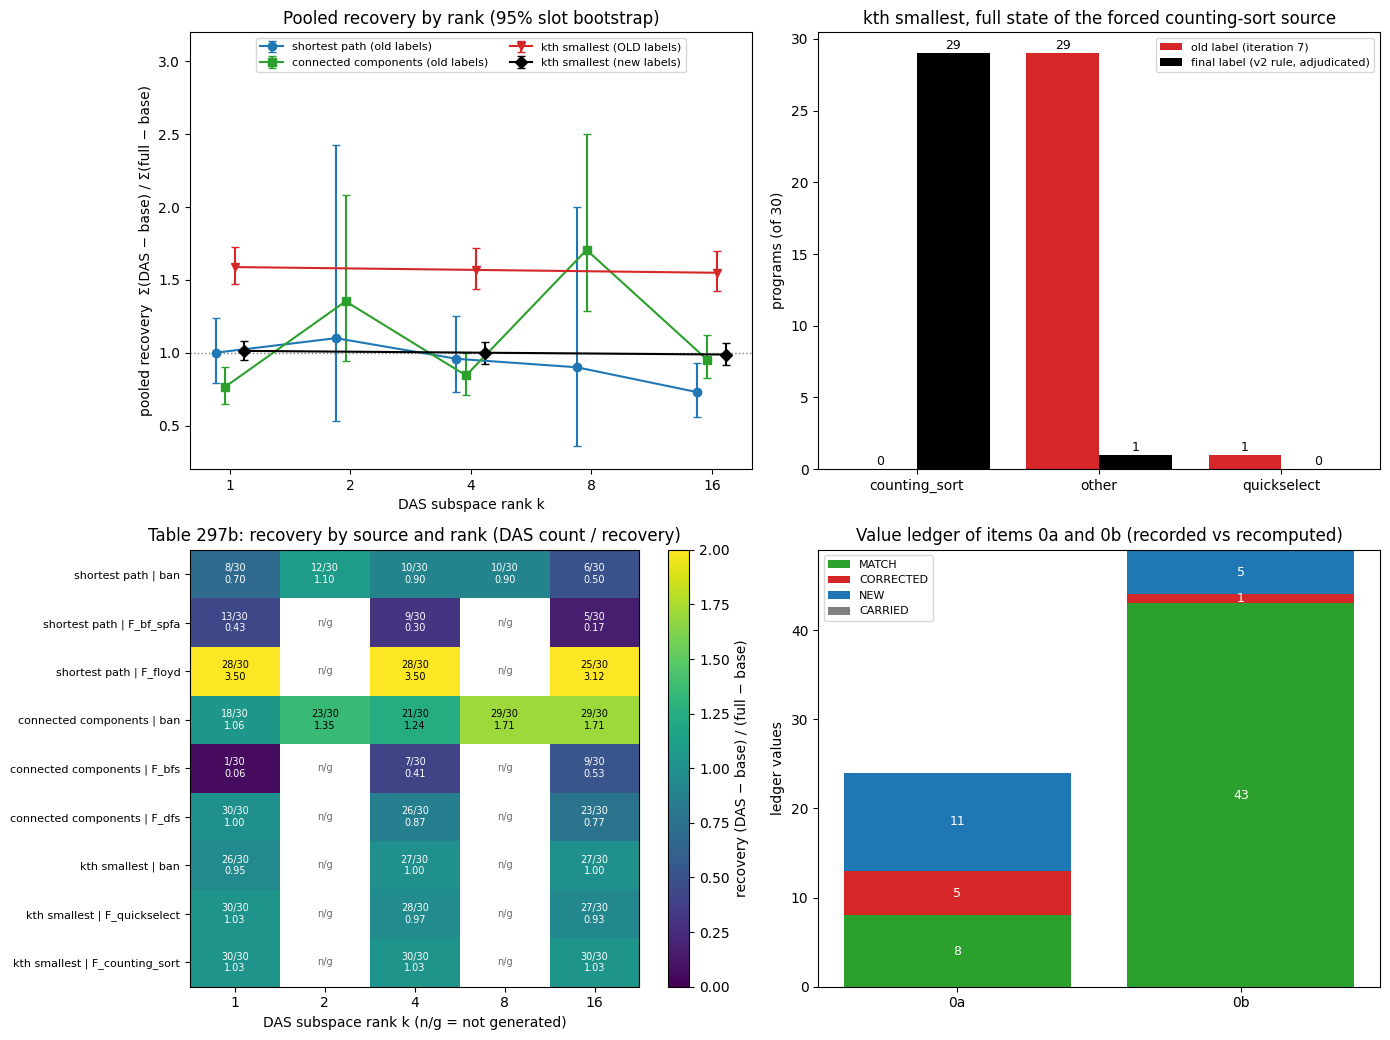

In [26]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10.5))
TN = {"T2": "shortest path", "T10": "connected components", "T03": "kth smallest"}

# 1) pooled recovery by rank, with the slot-bootstrap 95% interval
ax = axs[0, 0]
series = [("T2", a5["old"]["T2"], "old labels", "tab:blue", "o"), ("T10", a5["old"]["T10"], "old labels", "tab:green", "s"),
          ("T03", a5["old"]["T03"], "OLD labels", "tab:red", "v"), ("T03", a5["new"]["T03"], "new labels", "black", "D")]
for j, (t, res, lab, col, mk) in enumerate(series):
    ks = [k for k in (1, 2, 4, 8, 16) if res["per_k"][k]["recovery"] is not None]
    y = np.array([res["per_k"][k]["recovery"] for k in ks])
    lo = np.array([res["per_k"][k]["recovery_ci"][0] for k in ks])
    hi = np.array([res["per_k"][k]["recovery_ci"][1] for k in ks])
    x = np.log2(ks) + (j - 1.5) * 0.08
    ax.errorbar(x, y, yerr=[y - lo, hi - y], fmt=mk + "-", color=col, capsize=3, label=f"{TN[t]} ({lab})")
ax.axhline(1, color="grey", ls=":", lw=1)
ax.set_xticks(np.log2([1, 2, 4, 8, 16]), [1, 2, 4, 8, 16])
ax.set_xlabel("DAS subspace rank k")
ax.set_ylabel("pooled recovery  Σ(DAS − base) / Σ(full − base)")
ax.set_title("Pooled recovery by rank (95% slot bootstrap)")
ax.set_ylim(0.2, 3.2)
ax.legend(fontsize=8, ncol=2, loc="upper center")

# 2) the full-state cell of the forced counting-sort source, before and after the relabel
ax = axs[0, 1]
cell = [r for r in a4["rows"] if r["cell"] == "FULL_F_counting_sort"]
labs = sorted({r["old_label"] for r in cell} | {r["final_label"] for r in cell})
o = Counter(r["old_label"] for r in cell)
f = Counter(r["final_label"] for r in cell)
xx = np.arange(len(labs))
ax.bar(xx - 0.2, [o[l] for l in labs], 0.4, label="old label (iteration 7)", color="tab:red")
ax.bar(xx + 0.2, [f[l] for l in labs], 0.4, label="final label (v2 rule, adjudicated)", color="black")
for xi, l in zip(xx, labs):
    ax.text(xi - 0.2, o[l] + 0.3, o[l], ha="center", fontsize=9)
    ax.text(xi + 0.2, f[l] + 0.3, f[l], ha="center", fontsize=9)
ax.set_xticks(xx, labs)
ax.set_ylabel("programs (of 30)")
ax.set_title("kth smallest, full state of the forced counting-sort source")
ax.legend(fontsize=8)

# 3) Table 297b: recovery by source and rank (item 0b)
ax = axs[1, 0]
if "0b" in items_all:
    import csv as _csv
    rb = list(_csv.DictReader((TABLES / "recovery_by_source.csv").open()))
    srcs = list(dict.fromkeys((r["task"], r["source"]) for r in rb))
    M = np.full((len(srcs), 5), np.nan)
    txt = [["" for _ in range(5)] for _ in srcs]
    for r in rb:
        i, j = srcs.index((r["task"], r["source"])), (1, 2, 4, 8, 16).index(int(r["rank"]))
        if r["generated"] == "y":
            txt[i][j] = f"{r['das_count']}/30\n" + (r["recovery"] if r["recovery"] == "undefined" else f"{float(r['recovery']):.2f}")
            if r["recovery"] != "undefined":
                M[i, j] = float(r["recovery"])
        else:
            txt[i][j] = "n/g"
    im = ax.imshow(M, cmap="viridis", vmin=0, vmax=2, aspect="auto")
    for i in range(len(srcs)):
        for j in range(5):
            ax.text(j, i, txt[i][j], ha="center", va="center", fontsize=7,
                    color="dimgray" if np.isnan(M[i, j]) else ("white" if M[i, j] < 1.2 else "black"))
    ax.set_xticks(range(5), [1, 2, 4, 8, 16])
    ax.set_yticks(range(len(srcs)), [f"{TN[t]} | {s}" for t, s in srcs], fontsize=8)
    ax.set_xlabel("DAS subspace rank k (n/g = not generated)")
    ax.set_title("Table 297b: recovery by source and rank (DAS count / recovery)")
    fig.colorbar(im, ax=ax, label="recovery (DAS − base) / (full − base)")
else:
    ax.axis("off")
    ax.text(0.5, 0.5, 'item 0b not run (add "b" to STAGES)', ha="center")

# 4) the value ledger of the items that ran, by status
ax = axs[1, 1]
its = [it for it in ("0a", "0b") if it in items_all]
bottom = np.zeros(len(its))
for st, col in (("MATCH", "tab:green"), ("CORRECTED", "tab:red"), ("NEW", "tab:blue"), ("CARRIED", "tab:grey")):
    h = np.array([sum(v["status"] == st for v in items_all[it]["values"]) for it in its], dtype=float)
    ax.bar(its, h, bottom=bottom, color=col, label=st)
    for xi, (b, hh) in enumerate(zip(bottom, h)):
        if hh:
            ax.text(xi, b + hh / 2, int(hh), ha="center", va="center", color="white", fontsize=9)
    bottom += h
ax.set_ylabel("ledger values")
ax.set_title("Value ledger of items 0a and 0b (recorded vs recomputed)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Three of the machine-checkable report edits

Each edit replaces one passage (`old_text`, which occurs exactly once in the iteration-7 report) with corrected text.

In [27]:
if "0a" in items_all:
    for e in items_all["0a"]["edits"]:
        if e["id"] in ("C8-a01", "C8-a05", "C8-a10"):
            print(f"[{e['id']}] item {e['item']}, {e['section']} ({e['kind']})\n  OLD: {e['old_text']}\n  NEW: {e['new_text']}\n")

[C8-a01] item 0a, 7.3.4 (prose)
  OLD: on kth smallest the forced counting sort source transfers 30 of 30 at every rank while the full state exchange gives 0 (29 programs labelled other, read below).
  NEW: on kth smallest the forced counting sort source transfers 30 of 30 at every rank, and the full state exchange of the same prompt gives 29 of 30: the 29 programs once labelled other are counting sort in dictionary form (counts in a dictionary walked in sorted key order), which the extended labeller now names counting sort, and the remaining program is a binary search on the value range (Table 300) (iteration-8 correction).

[C8-a05] item 0a, Table 297 (table_row)
  OLD: | 1 | 1.59 [1.47, 1.72] | 0.05 | 20:0 (1.9e-06) | 0.60 | 0.90 |
  NEW: | 1 | 1.01 [0.95, 1.08] | 0.05 | 20:0 (1.9e-06) | 0.60 | 0.90 |

[C8-a10] item 0a, Table 300 (table_row)
  OLD: | kth smallest | counting sort | 0.00 (0/30) [0.00, 0.12] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 